# 19 · Convergence with the pixel width (TNG50-2, the `pixels` sweep)


How fine must the pixels be? The optical depth is computed at the centre of every pixel (the integrated profile:
exact for any piece, but sampled at the pixel centres), so a coarse pixel gives $F = e^{-\tau}$ at its centre, not the
flux averaged over the pixel. Five nominal widths, 10, 5, 1, 0.5 and 0.1 km/s (the grid tiles the velocity period
exactly: the actual width is the period over an integer number of pixels, listed in Part A), on the fiducial run's
skewers (TNG50-2 snapshot 25, $128 \times 128$ along $y$, the exact crossings, the integrated profile, the exact frame, $a(s)$
every 0.05 cMpc; `run_production.py --sweep pixels`). The reference is 0.1 km/s. Every coarser run is compared twice:
with the 0.1 km/s run itself on the modes and bins they share, and with **the 0.1 km/s transmission averaged over each
coarse pixel** (`rebin_pixels`: every fine pixel weighted by its overlap with the coarse one; the overflux and the
statistics then recomputed on the coarse grid), which is what a spectrograph with that pixel would record from the
fine spectrum: that comparison isolates the error of evaluating $\tau$ at the pixel centres. The averaged flux is not defined
order by order (the pixel average of the total is not the product of the averaged lines), so in Parts D and E
the totals use it and the orders and terms the 0.1 km/s run as it is.


Every run is a folder of `scripts/production/run_production.py` (`<OUT>/<SWEEP>/<run>/run.json`) that names its
lattice in the campaign's skewer store; `load_run` reads it. The statistics follow notebooks 11 and 18 on **one line of
sight** ($y$): the transmission $T = e^{-\tau}$ of every line and of the total, its mean $\bar T$, the overflux
$\delta = T/\bar T - 1$, P1D on its native modes and $P(k, \mu)$ of the total in four wedges, and both split
order by order and term by term on the 16 wedges of notebook 11 (`summary_stats.run_statistics`). One line of sight gives no ensemble, so the errors come from a **delete-one-block
jackknife**: the lattice is cut into $4 \times 4$ squares of skewers and each sample leaves one square out (the
3D power of the field with that square set to zero, divided by the fraction kept). Every run is compared with the
reference **bin by bin**, as the relative difference $X_{\rm run}/X_{\rm ref} - 1$, with the jackknife error of that
ratio (`compare_runs`): the runs share the skewer positions and the blocks, so the sample variance they share cancels.
The last part gives, per run, **the largest $k$ up to which every bin differs by less than 0.1%, 0.5% and 1%**
(`k_max_table`; P1D on every native mode, $P(k, \mu)$ on every $|k|$ bin).

Colours: the fiducial run of the campaign in black in every notebook; the other runs from light (coarse) to dark (fine)
on one scale shared by notebooks 18–21.


- **Part A — the stored skewers read back:** every run's lattice, pixels, sampling and dataset, and the checks of the
  pairing (the same skewers and period in every run).
- **Part B — the statistics of every run** and their comparison with the reference.
- **Part C — the mean transmission.**
- **Part D — P1D by order and by term:** D1 the total and orders 2–4, D2 the order-2 terms (the autos of
  $\mathrm{Ly}\alpha$ and Si III, their cross), every run against the 0.1 km/s run.
- **Part E — $P(k, \mu)$ by order and by term in 16 wedges:** E1 the total and orders 2–4, E2 the order-2 terms,
  one figure each.
- **Part F — the converged range:** the largest $k$ within 0.1%, 0.5% and 1% of the reference, and what it implies.

In [1]:
import os
from pathlib import Path

# ---- configuration: the sweep (scripts/production/run_production.py --sweep pixels)
SWEEP = "pixels"
RUNS = ["dv_10kms", "dv_5kms", "dv_1kms", "dv_0p5kms", "dv_0p1kms"]   # coarse to fine
REFERENCE = "dv_0p1kms"                           # the finest pixels: the reference
FIDUCIAL = "dv_1kms"                              # the fiducial run (black in every figure)
TERMS_REF = REFERENCE                             # the reference of Parts D and E: the finest pixels, as they are
ORDER = RUNS
DV_NOMINAL = {"dv_10kms": 10.0, "dv_5kms": 5.0, "dv_1kms": 1.0, "dv_0p5kms": 0.5, "dv_0p1kms": 0.1}   # [km/s]
RUN_LABELS = {r: f"{x:g} km/s" for r, x in DV_NOMINAL.items()}
TITLE_STEM = "Pixel width"
LINTHRESH = 0.01                                  # [%]: the residual axes are linear within it
OUT = Path(os.environ.get("SKEWERJAX_PRODUCTION", Path.home() / "skewerjax_production"))   # the --out of the campaign
N_SUB = None                                      # None: each run's lattice; 32: a quick check on the nested 32^2 sub-lattice
N_BLOCKS = 4                                      # jackknife: N_BLOCKS x N_BLOCKS squares of skewers
MU_EDGES = (0.0, 0.5, 0.8, 0.95, 1.0)             # the four wedges of P(k, mu) (notebooks 10 and 11's wedges of xi)
TOLS = (0.001, 0.005, 0.01)                       # the convergence levels of Part F
N_MU_TERMS = 16                                   # Parts D and E: the wedges of notebook 11, even in the angle to the line of sight
RES_LINTHRESH = 0.01                              # [%]: the residual rows of Parts D and E are linear within it
X_OF_RUN, X_LABEL, X_SCALE, X_TICKS = DV_NOMINAL, "pixel width $dv$ [km s$^{-1}$]", "log", None

# ---- imports
os.environ.setdefault("JAX_PLATFORMS", "cpu")
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)
import json, sys, time
import numpy as np
import matplotlib.pyplot as plt
from skewerjax.utils.plotting import use_style, use_backend
# use_backend()                                    # interactive figures in a live notebook
use_style()
from skewerjax.utils.plotting import (TERM_ORDERS, add_panel_letters, field_names, order2_terms, run_styles,
                                      plot_runs_mean_flux, plot_runs_p1d_orders, plot_runs_p1d_terms, plot_runs_pk_mu_orders,
                                      plot_runs_pk_mu_terms, plot_k_max_summary)
from skewerjax.summary_stats import (LatticeWedges, block_labels, compare_runs, format_k_max_table, format_terms_table,
                                     k_max_table, rebin_pixels, run_statistics, set_k_edges)
from skewerjax.utils.reference_data import P1D_DESI_DR1, nearest_reference
from skewerjax.utils.paths import PRODUCTION_DIR, PRODUCTION_SCRIPTS_DIR   # the run folders; the reader of the skewer store
sys.path.insert(0, str(PRODUCTION_SCRIPTS_DIR))
from skewer_store import load_run
from skewerjax.utils.plotting import PALETTE

## Part A — The stored skewers read back

- `OUT`, `SWEEP`, `RUNS`: the run folders `<OUT>/<SWEEP>/<run>`; `REFERENCE` the 0.1 km/s run.
- `N_SUB`: `None` reads each run's $128 \times 128$ lattice; 32 its nested $32 \times 32$ sub-lattice (a quick check).

The checks: every run has the same skewers and the same velocity period (so the P1D modes $k_m = 2\pi m/v_{\rm per}$
coincide up to the coarser Nyquist frequency, and a coarse pixel is an exact interval of fine ones' grid).

In [2]:
RECS = {r: json.loads((OUT / SWEEP / r / "run.json").read_text()) for r in RUNS}
S = {r: load_run(OUT / SWEEP / r, N_SUB) for r in RUNS}          # tau (n_lines, N_sk, N_pix), positions, columns, v, dv, L, u
REF = S[REFERENCE]
L, U, PERIOD = REF.L, REF.u, REF.period                          # [cMpc], aH [km/s per cMpc], v_per [km/s]
N = REF.n_per_axis
Z, A_SNAP = RECS[REFERENCE]["snapshot"]["redshift"], RECS[REFERENCE]["snapshot"]["a"]
LINE_IDS = REF.line_ids
FIELDS = (*LINE_IDS, "total")
NAMES = field_names(FIELDS)
print(f"{'run':<13} {'sim':<8} {'lattice':>8} {'N_pix':>6} {'dv [km/s]':>10} {'dx [cMpc]':>10} {'dx [km/s]':>10} {'route':<10} "
      f"{'dataset':<11} {'computed':>8} {'wall':>8}")
for r in RUNS:
    rec, s, sm = RECS[r], S[r], RECS[r]["sampling"]
    print(f"{r:<13} {s.sim:<8} {s.n_per_axis:>5}^2 {s.v.size:>6} {s.dv:>10.4f} {sm['points_cMpc']:>10.3g} {sm['points_kms']:>10.3g} "
          f"{sm['route']:<10} {rec['dataset']['hash']:<11} {rec['timings']['computed']:>8} {rec['wall_s']:>7.0f}s")
    assert np.isfinite(s.tau).all(), r
for r in RUNS:                                    # tau < 0: the round-off of the engine (float32), relative to each skewer's peak
    t = S[r].tau
    neg = t < 0
    if neg.any():
        worst = (-t.min(axis=-1) / t.max(axis=-1)).max(axis=-1)       # (n_lines,) the largest |tau_min| / tau_max of a skewer
        print(f"{r}: tau < 0 in {neg.mean():.2%} of the samples (" + ", ".join(
              f"{NAMES[l]}: min {t[j].min():.2g}, |min| / max per skewer <= {worst[j]:.1e}" for j, l in enumerate(LINE_IDS) if t[j].min() < 0) + ")")
print(f"\nreference {REFERENCE}: {REF.sim} snapshot {REF.snap}, z = {Z:.4f}, L = {L:.3f} cMpc, u = {U:.3f} km/s per cMpc (1 km/s = {1 / U:.5f} cMpc), "
      f"v_per = {PERIOD:.2f} km/s; tau finite in every run")
print("sampling of the reference: " + RECS[REFERENCE]["sampling"]["effect"])

for r in RUNS:
    assert np.array_equal(S[r].positions, REF.positions) and abs(S[r].period - PERIOD) < 1e-9 * PERIOD, r
print("the same skewers and period in every run; actual widths: " + ", ".join(f"{r}: {S[r].dv:.5f} km/s" for r in RUNS))

run           sim       lattice  N_pix  dv [km/s]  dx [cMpc]  dx [km/s] route      dataset     computed     wall
dv_10kms      TNG50-2    128^2    394    10.0249       0.05       3.83 streaming  85666c37ce     16384     127s
dv_5kms       TNG50-2    128^2    789     5.0061       0.05       3.83 streaming  ed258b126e     16384     126s
dv_1kms       TNG50-2    128^2   3949     1.0002       0.05       3.83 streaming  e228cdc7b9         0       1s
dv_0p5kms     TNG50-2    128^2   7899     0.5000       0.05       3.83 streaming  5b526622f3     16384     155s
dv_0p1kms     TNG50-2    128^2  39498     0.1000       0.05       3.83 streaming  96dc1e9d2a     16384     296s
dv_0p1kms: tau < 0 in 3.77% of the samples (Si III: min -0.014, |min| / max per skewer <= 6.1e-05)

reference dv_0p1kms: TNG50-2 snapshot 25, z = 3.0081, L = 51.668 cMpc, u = 76.673 km/s per cMpc (1 km/s = 0.01304 cMpc), v_per = 3949.82 km/s; tau finite in every run
sampling of the reference: the a(s) table of the exact frame

## Part B — The statistics of every run

The 3D bins are set by the lattice: $|k|$ one bin per mode up to $3.5\,k_f$, steps of $0.4\,k_f$
to 2 cMpc$^{-1}$, then 12 logarithmic bins to the transverse Nyquist frequency $\pi N/L$; the four wedges of
`MU_EDGES` in $\mu = k_\parallel/|k|$. P1D stays on its native modes $k_m = 2\pi m/v_{\rm per}$ for the checks, and is
averaged in 40 logarithmic bins for the figures only. Each line gives the time of each step of a run.

Then the rebinned reference: the transmission of the 0.1 km/s run (every line and the total, the product at full
resolution) averaged over the pixels of each coarser run (`rebin_pixels`), and its statistics on that run's grid.

**The decomposition of Parts D and E:** `run_statistics(terms_grid=)` also splits P1D and $P(k, \mu)$ of the total
into its orders and order-2 terms, with the same jackknife, in the 16 wedges of `MU_EDGES_TERMS` on the same $|k|$
bins (`LatticeWedges(store_index=False)`: the transforms along the line of sight first, then across the lattice one
slab of $k_\parallel$ at a time). Two checks are printed per run: the sum of the orders against the total (the sum
rule), and the total against P1D and the four wedges of $P(k, \mu)$ above (the largest difference relative to the
largest value).

In [3]:
KF = 2 * np.pi / L
K_NYQ = np.pi * N / L                                            # the transverse Nyquist frequency of the lattice [1/cMpc]
K_EDGES = set_k_edges(KF, k_1=3.5 * KF, k_2=min(2.0, K_NYQ), k_max=K_NYQ, dk_factor=0.4, n_log=12)
K1D_EDGES = np.geomspace(2 * np.pi / PERIOD, np.pi / min(S[r].dv for r in RUNS), 41)   # display bins of P1D [s/km]
P1D_REF = nearest_reference(P1D_DESI_DR1, Z)
K_DESI = float(np.max(P1D_REF["k"]))                             # [s/km]: the largest k of DESI DR1 at the snapshot's z
MU_EDGES_TERMS = np.sin(np.linspace(0.0, np.pi / 2, N_MU_TERMS + 1))   # the wedges of Parts D and E
GRIDS = {}


def grid_for(n, n_pix):
    """The mu wedges of P on an n x n lattice of n_pix pixels (LatticeWedges: the bins of lattice_grid's P_mu alone, the memory of
    512^2 lattices), cached: the same |k| edges and mu wedges for every run."""
    if (n, n_pix) not in GRIDS:
        GRIDS[n, n_pix] = LatticeWedges(n, n_pix, L, k_edges=K_EDGES, mu_edges=MU_EDGES)
    return GRIDS[n, n_pix]


def terms_grid_for(n, n_pix):
    """The 16 wedges of the decomposition (Parts D and E), without an index (streamed by run_statistics)."""
    if (n, n_pix, "terms") not in GRIDS:
        GRIDS[n, n_pix, "terms"] = LatticeWedges(n, n_pix, L, k_edges=K_EDGES, mu_edges=MU_EDGES_TERMS, store_index=False)
    return GRIDS[n, n_pix, "terms"]


def statistics(s, transmissions=None, n_pix=None, dv=None, decompose=True):
    """run_statistics of one run (or of ``transmissions`` on ``n_pix`` pixels of ``dv``) on its lattice's jackknife blocks
    and bins, T_bar the mean over every pixel (one scale factor: the box), with the time of each step; with its
    decomposition by order and term on the 16 wedges (decompose=False: the total alone)."""
    n_pix = s.v.size if n_pix is None else n_pix
    steps = []
    out = run_statistics(None if transmissions is not None else s.tau, s.dv if dv is None else dv, line_ids=LINE_IDS,
                         labels=block_labels(s.columns, s.n_per_axis, N_BLOCKS), grid=grid_for(s.n_per_axis, n_pix),
                         transmissions=transmissions, a_pix=np.full(n_pix, A_SNAP), log=steps.append,
                         terms_grid=terms_grid_for(s.n_per_axis, n_pix), decompose=decompose)
    return out, steps


STATS, T0 = {}, time.perf_counter()
for r in RUNS:
    t = time.perf_counter()
    STATS[r], steps = statistics(S[r])
    print(f"{r:<13} {time.perf_counter() - t:6.1f} s: " + "; ".join(steps))
    tr = STATS[r]["terms"]
    print(f"{'':<13} sum of the orders vs the total: P1D {tr['sum_rule']['p1d']:.1e}, P(k, mu) {tr['sum_rule']['P_mu']:.1e}; "
          f"the total vs P1D and the 4 wedges above: {tr['check']['p1d']:.1e}, {tr['check']['P_mu']:.1e}")
CMP = {r: compare_runs(STATS[r], STATS[REFERENCE], k_edges_1d=K1D_EDGES) for r in RUNS if r != REFERENCE}   # display bins
CMP_ALL = {r: compare_runs(STATS[r], STATS[REFERENCE]) for r in RUNS if r != REFERENCE}                  # every mode: the checks
STYLES = run_styles(ORDER, fiducial=FIDUCIAL)
CMP_T = CMP                                                      # Parts D and E: against TERMS_REF
print(f"every run in {time.perf_counter() - T0:.0f} s; P(k, mu) in {len(MU_EDGES) - 1} wedges x {len(K_EDGES) - 1} |k| bins up to "
      f"{K_NYQ:.2f} cMpc^-1; jackknife over {N_BLOCKS} x {N_BLOCKS} squares of {N // N_BLOCKS} x {N // N_BLOCKS} skewers")

T_FINE = np.exp(-REF.tau)
T_FINE = np.concatenate([T_FINE, T_FINE.prod(axis=0, keepdims=True)])   # (n_lines + 1, N_sk, N_pix): the lines and the total
STATS_REB, CMP_REB, CMP_REB_ALL = {}, {}, {}
for r in RUNS:
    if r == REFERENCE:
        continue
    t = time.perf_counter()
    T_r = rebin_pixels(T_FINE, S[r].v.size)
    STATS_REB[r], _ = statistics(REF, transmissions=T_r, n_pix=S[r].v.size, dv=S[r].dv, decompose=False)   # the total alone
    CMP_REB[r] = compare_runs(STATS[r], STATS_REB[r], k_edges_1d=K1D_EDGES)
    CMP_REB_ALL[r] = compare_runs(STATS[r], STATS_REB[r])
    print(f"{r}: the rebinned 0.1 km/s transmission ({S[r].v.size} pixels) in {time.perf_counter() - t:.1f} s")
    del T_r
del T_FINE
TERMS = order2_terms(CMP_T)                                      # the order-2 terms of D2 and E2: the autos, the cross
K_LIMITS_T = (2 * np.pi / PERIOD, np.pi / min(S[r].dv for r in CMP_T))   # [s/km]: the P1D range the runs share with TERMS_REF

dv_10kms         6.2 s: transmissions of 16,384 skewers x 394 pixels (0.2 s); P1D of HI-LyA (0.2 s); P1D of SiIII-1206 (0.2 s); P1D of total (0.2 s); P(k, mu) of total and its 16 jackknife samples (1.1 s); the transforms along the line of sight and P1D of 11 pairs (0.6 s); P(k, mu) of 11 pairs and their 16 jackknife samples in slabs of 32 k_par (3.3 s)
              sum of the orders vs the total: P1D 1.6e-09, P(k, mu) 4.8e-08; the total vs P1D and the 4 wedges above: 4.4e-16, 1.5e-07
dv_5kms         30.8 s: transmissions of 16,384 skewers x 789 pixels (0.5 s); P1D of HI-LyA (0.6 s); P1D of SiIII-1206 (0.6 s); P1D of total (0.6 s); P(k, mu) of total and its 16 jackknife samples (3.0 s); the transforms along the line of sight and P1D of 11 pairs (18.9 s); P(k, mu) of 11 pairs and their 16 jackknife samples in slabs of 32 k_par (5.7 s)
              sum of the orders vs the total: P1D 1.8e-09, P(k, mu) 9.8e-08; the total vs P1D and the 4 wedges above: 2.7e-16, 1.8e-07
dv_1kms         81.

## Part C — The mean transmission

$\bar F$ of every line and of the total, per run, as $100\,(\bar F_{\rm run}/\bar F_{\rm ref} - 1)$ [%] with its
jackknife error (the reference is the line at 0; the grey band is $\pm 0.5\%$, the dotted lines $\pm 0.1\%$ and
$\pm 1\%$; the axis is linear within `LINTHRESH`).

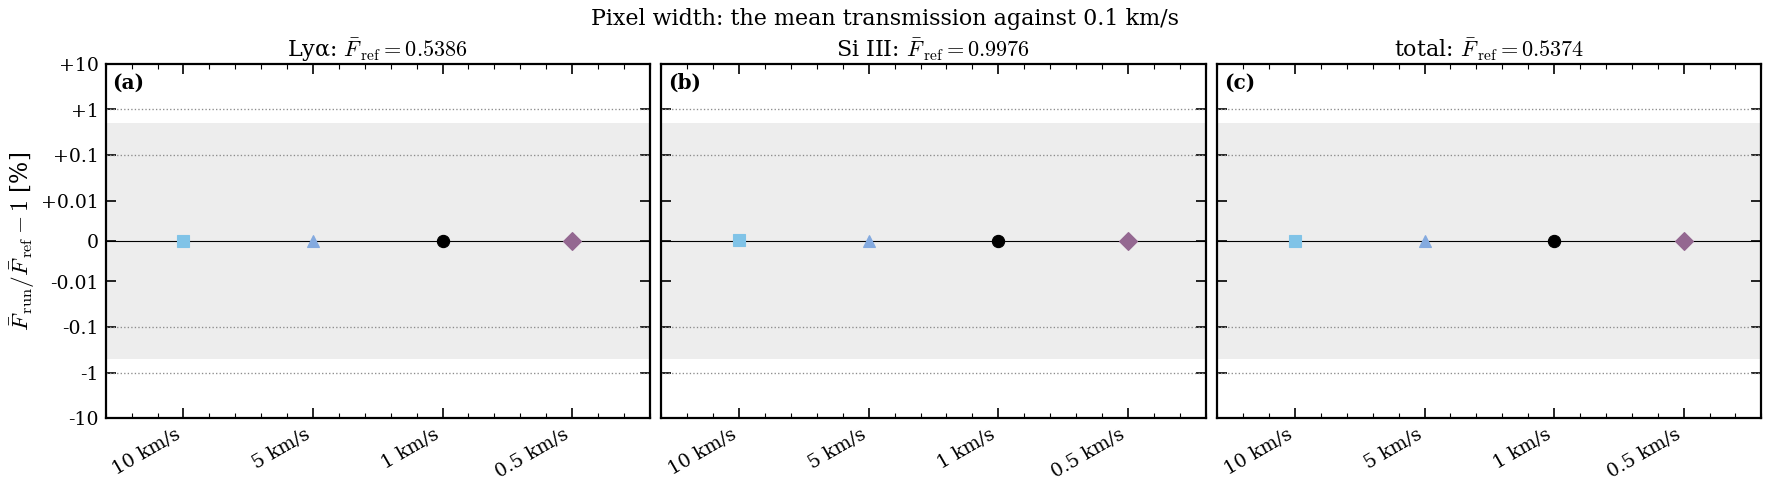

dv_10kms      Lyα: +5.5e-06 +- 1.1e-05 %; Si III: +0.000185 +- 0.00018 %; total: +1.94e-05 +- 0.00025 %
dv_5kms       Lyα: +1.99e-06 +- 2.2e-07 %; Si III: +3.02e-05 +- 5.1e-05 %; total: +3.44e-05 +- 4.6e-05 %
dv_1kms       Lyα: +3.4e-06 +- 4.5e-08 %; Si III: +3.2e-07 +- 8.2e-08 %; total: +3.7e-06 +- 1.3e-07 %
dv_0p5kms     Lyα: -7.62e-07 +- 1.7e-08 %; Si III: +2.38e-07 +- 4.5e-08 %; total: -5.73e-07 +- 3.3e-08 %


In [4]:
fig, axs = plot_runs_mean_flux(CMP, STYLES, REFERENCE, field_labels=NAMES, labels=RUN_LABELS, linthresh=LINTHRESH,
                               title=f"{TITLE_STEM}: the mean transmission against {RUN_LABELS[REFERENCE]}")
add_panel_letters(axs)
plt.show()
for r, c in CMP_ALL.items():
    print(f"{r:<13} " + "; ".join(f"{NAMES[f]}: {100 * c['mean_flux']['rel'][j]:+.3g} +- {100 * c['mean_flux']['err'][j]:.2g} %"
                                  for j, f in enumerate(FIELDS)))

## Part D — P1D by order and by term

**The orders and the terms** (notebook 11, Parts E and F; `docs/decomposition.md`). With $\delta_j = T_j/\bar T_j - 1$
the overflux of line $j$ and $\mathcal C = \bar T/\prod_j \bar T_j - 1$, the total overflux is exactly a sum of subset
fields, $\delta_{\rm tot} = \sum_A F_A$, with $F_\emptyset = -\mathcal C/(1+\mathcal C)$ and
$F_A = \prod_{j\in A}\delta_j/(1+\mathcal C)$. Every two-point statistic of the total is then the sum of the
cross-statistics of the pairs $(A, B)$, grouped by the order $n = |A| + |B| = 0, \dots, 4$ for two lines:

* **order 2:** the $\mathrm{Ly}\alpha$ auto ($F_{\rm Ly\alpha}$ with itself), the Si III auto, their cross
  ($2\,\mathrm{Re}\,P_{\rm Ly\alpha, Si\,III}$, which oscillates as $\cos(k_\parallel \Delta v)$ with the separation
  $\Delta v$ of the lines) and a $\mathcal C$ term;
* **order 3:** each line with the product of the two; **order 4:** the product with itself.

**Orders 0 and 1 are not shown.** They hold only the $\mathcal C$ terms, the corrections of the mean, which vanish on
average. In one snapshot $\mathcal C$ is a single number (`MEAN = "redshift"` with one $a$), so $F_\emptyset$ is a
constant whose power lives at $k = 0$ alone, which P1D at $k > 0$ and $P(k, \mu)$ leave out; the $\mathcal C$ term of
order 2 vanishes alike. At every $k > 0$: total = order 2 + order 3 + order 4 (the sum rule printed in Part B).

**The figures.** Every run against **the 0.1 km/s run** (the highest level of the sweep), drawn thick and light underneath with
its jackknife error as a faint band. Above, $kP_{\rm 1D}/\pi$ in 40 logarithmic display bins. Below, the difference
$\Delta = X_{\rm run} - X_{\rm ref}$ in per cent of $|X_{\rm ref}|$, on the grey band of the reference's jackknife error:
a residual inside the band is not significant. The residual axis is symmetric-log, linear within `RES_LINTHRESH`. A
quantity that changes sign (the cross term, order 3) has a symmetric-log main axis, and where $|X_{\rm ref}|$ falls
below 1% of its maximum in the panel, $\Delta$ is divided by the local envelope of $|X_{\rm ref}|$ instead (its running
maximum over $\pm 2$ bins; open markers). The grey bands lie outside $[2\pi/v_{\rm per}, \pi/dv]$; the dashed line is the
largest $k$ of DESI DR1 at the snapshot's redshift. A coarse run stops at its own Nyquist frequency $\pi/dv$ in P1D.
The tables list, per run and quantity for $k \le k_{\rm DESI}$, the median and largest $|\Delta|$, the median error of
the reference, and the share of bins outside it.

### D1 · P1D by order

The total and orders 2, 3, 4. The total panel (a) is against the 0.1 km/s transmission averaged over each run's pixels (dashed, in the run's
colour, its own reference); the orders against the 0.1 km/s run as it is, so their residual includes the pixel
window that a coarse-pixel measurement has.

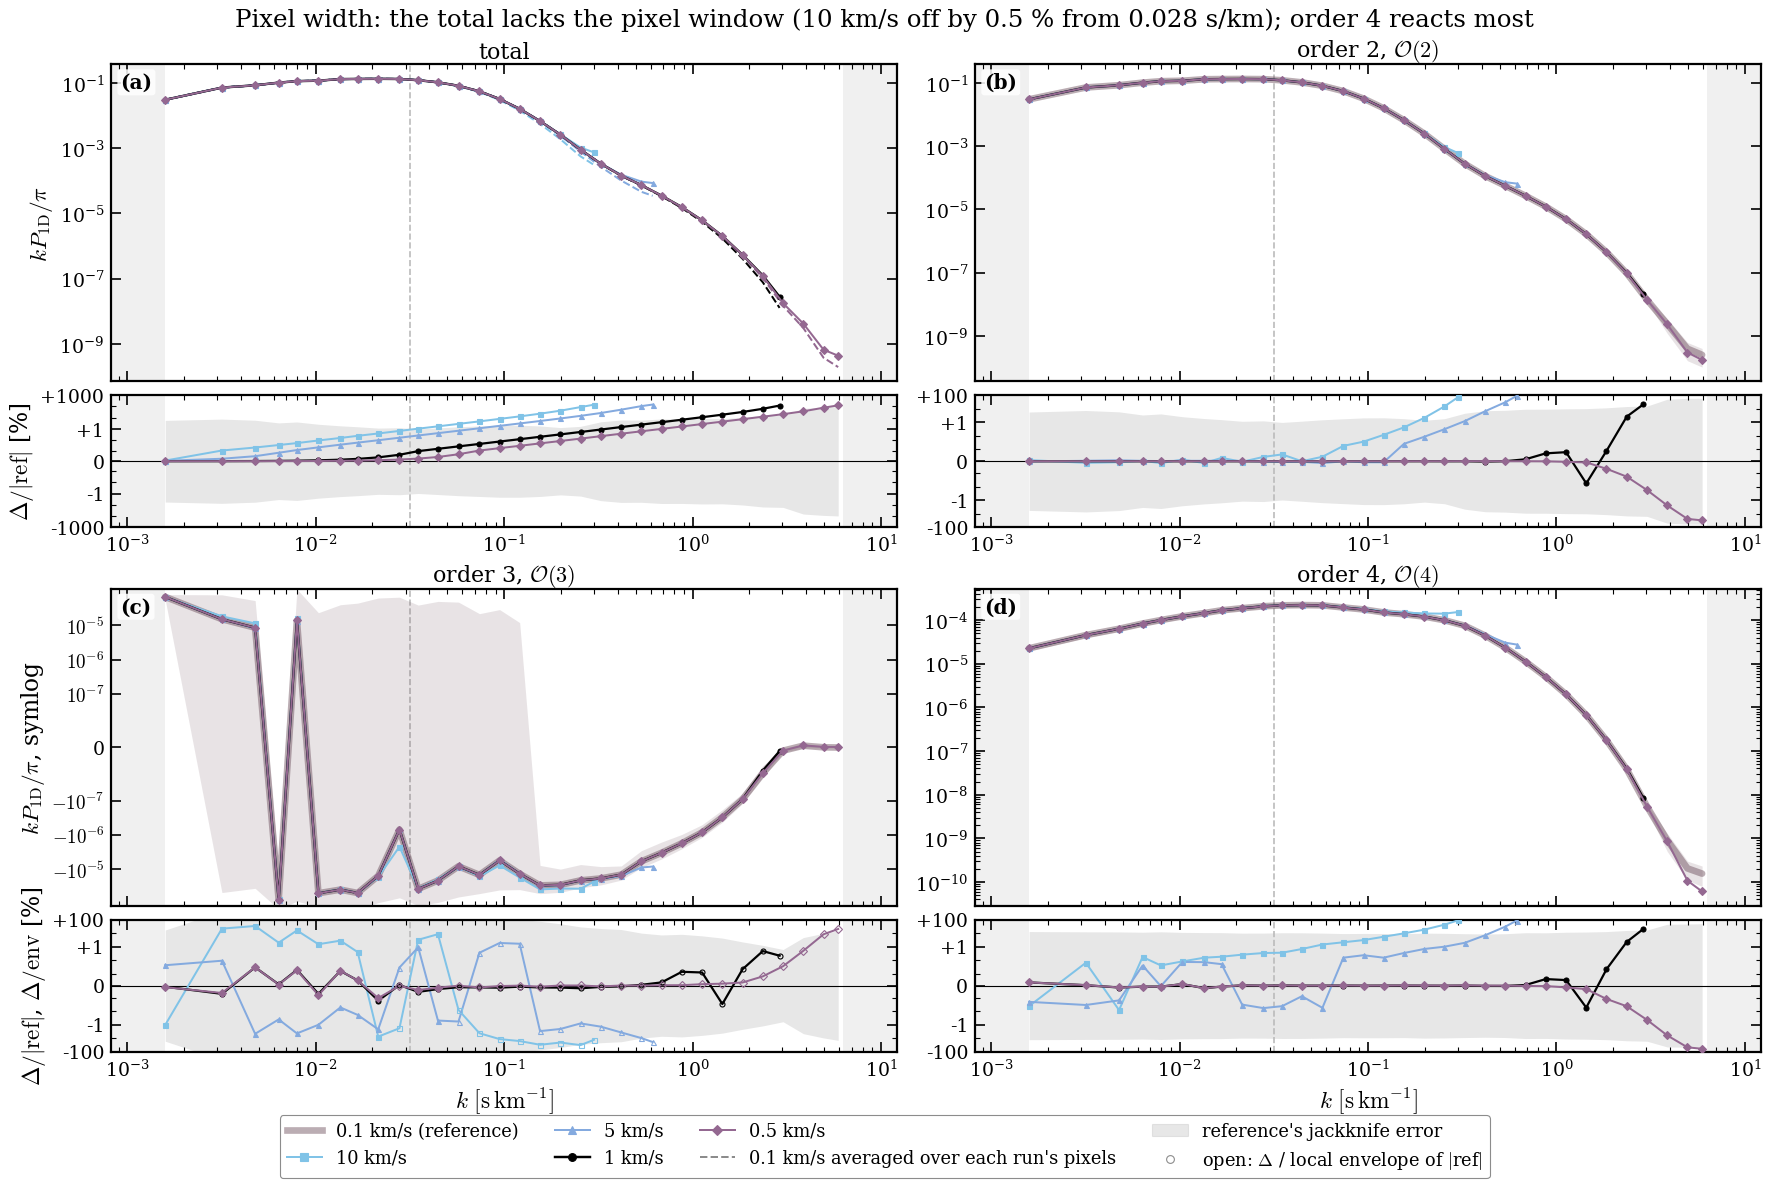

k <= 0.032 s/km, against dv_0p1kms; '(total)': the total against the 0.1 km/s run averaged over each run's pixels:
run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dv_10kms       total                               0.00198      0.00316        2.95       0%
dv_10kms       order 2                             0.00134      0.00358        2.97       0%
dv_10kms       order 3                                2.35         33.5         197       0%
dv_10kms       order 4                               0.117        0.334        11.4       0%
dv_5kms        total                              0.000318     0.000434        2.95       0%
dv_5kms        order 2                             0.00034     0.000778        2.97       0%
dv_5kms        order 3                                 0.3         4.77         197       0%
dv_5kms        order 4                              0.0373       0.0729        11.4       0%
dv_1kms        total                            

In [5]:
fig, main, res = plot_runs_p1d_orders(CMP_T, STYLES, TERMS_REF, line_ids=LINE_IDS, labels=RUN_LABELS, linthresh=RES_LINTHRESH,
                                      k_limits=K_LIMITS_T, k_mark=K_DESI,
                                      total_comparisons=CMP_REB, total_ref_label="0.1 km/s averaged over each run's pixels",
                                      title='Pixel width: the total lacks the pixel window (10 km/s off by 0.5 % from 0.028 s/km); order 4 reacts most')
add_panel_letters(main)
plt.show()
print(f"k <= {K_DESI:.3f} s/km, against {TERMS_REF}; '(total)': the total against the 0.1 km/s run averaged over each run's pixels:")
print(format_terms_table({**CMP_T, **{r + " (total)": c for r, c in CMP_REB.items()}}, TERM_ORDERS, "p1d", k_max=K_DESI))

*Reading.* Two references here. **The total (a)**, against the 0.1 km/s flux averaged over each pixel,
leaves its 0.5% level at $k$ = 0.028, 0.057, 0.25 and 0.54 s/km for 10, 5, 1 and 0.5 km/s, and grows as $k^2$: the pixel
window that $e^{-\tau}$ at the pixel centre lacks (10 km/s is +0.86% at the DESI limit). **The orders (b–d)**, against the
0.1 km/s run as it is, agree in the DESI range to $\le 0.12$% at 10 km/s (order 4; $2\times10^{-3}$% for order 2), far
inside their errors. Above 0.1 s/km order 4 rises by +18% at 10 km/s and order 2 by +2%; at each grid's own Nyquist
frequency every order shows the aliased excess.

### D2 · P1D term by term (order 2)

The $\mathrm{Ly}\alpha$ auto, the Si III auto and their cross term, against the 0.1 km/s run as it is.

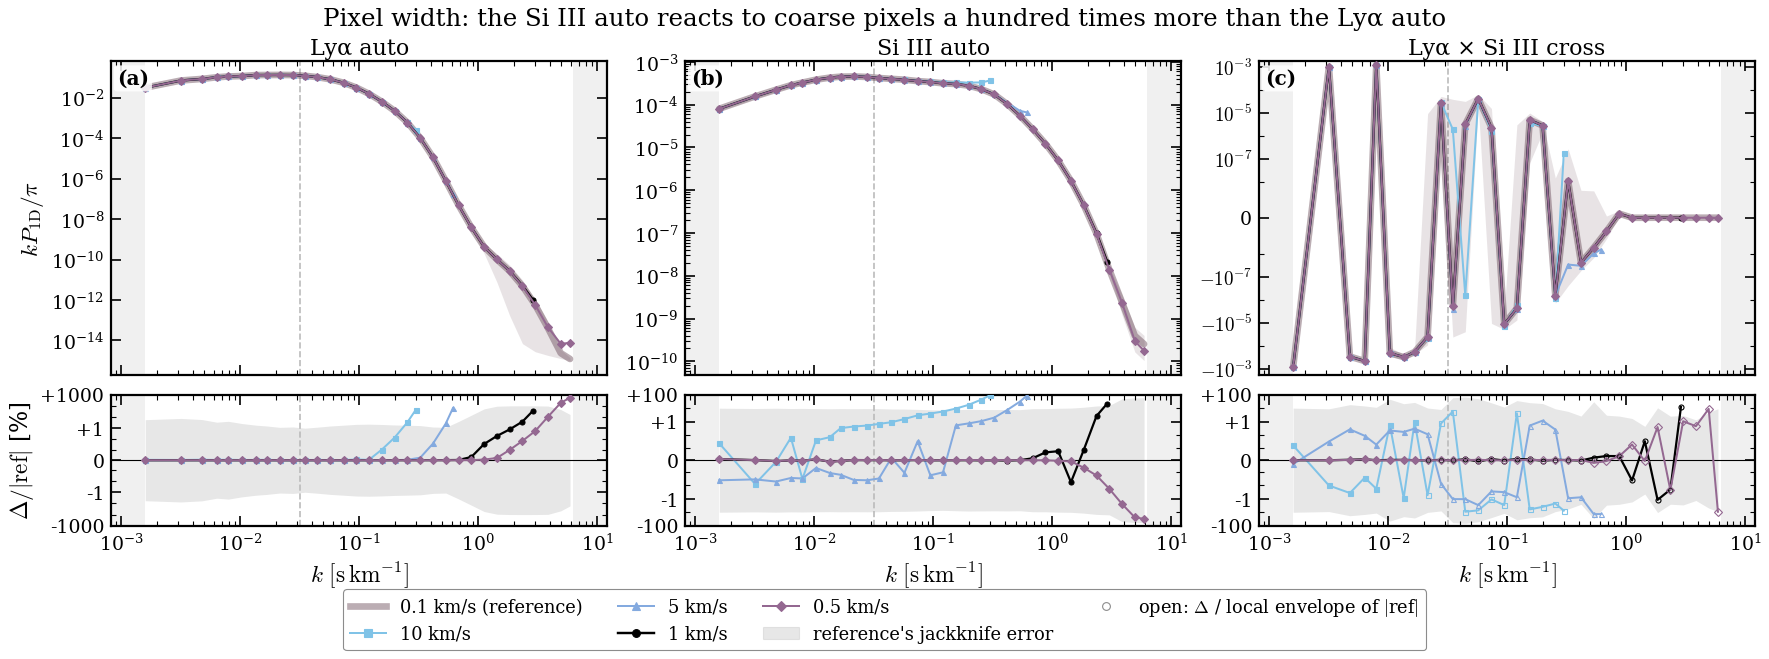

k <= 0.032 s/km, against dv_0p1kms:
run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dv_10kms       HI-LyA|HI-LyA                        0.0003     0.000494        2.96       0%
dv_10kms       SiIII-1206|SiIII-1206                0.0647          0.5        9.26       0%
dv_10kms       HI-LyA|SiIII-1206                     0.448        0.933        12.9       0%
dv_5kms        HI-LyA|HI-LyA                      1.03e-05      1.4e-05        2.96       0%
dv_5kms        SiIII-1206|SiIII-1206                0.0324       0.0506        9.26       0%
dv_5kms        HI-LyA|SiIII-1206                    0.0982        0.293        12.9       0%
dv_1kms        HI-LyA|HI-LyA                      8.56e-06     9.98e-06        2.96       0%
dv_1kms        SiIII-1206|SiIII-1206              0.000485       0.0013        9.26       0%
dv_1kms        HI-LyA|SiIII-1206                  0.000187     0.000768        12.9       0%
dv_0p5kms      HI-LyA|HI-LyA      

In [6]:
fig, main, res = plot_runs_p1d_terms(CMP_T, STYLES, TERMS_REF, terms=TERMS, line_ids=LINE_IDS, labels=RUN_LABELS,
                                     linthresh=RES_LINTHRESH, k_limits=K_LIMITS_T,
                                     k_mark=K_DESI, title="Pixel width: the Si III auto reacts to coarse pixels a hundred times more than the Lyα auto")
add_panel_letters(main)
plt.show()
print(f"k <= {K_DESI:.3f} s/km, against {TERMS_REF}:")
print(format_terms_table(CMP_T, TERMS, "p1d", k_max=K_DESI))

*Reading.* Against the 0.1 km/s run as it is. In the DESI range all three terms stay well inside their
errors. Above 0.1 s/km the Si III auto of 10 km/s rises by +18% (median), the $\mathrm{Ly}\alpha$ auto by +0.14%: the
Si III lines are $\sqrt{28/1}\approx 5$ times narrower in thermal width, so a 10 km/s pixel undersamples them and their
power above the Nyquist frequency folds back. The cross departs by $\sim 4$% (10 km/s) of its envelope; 1 km/s and
finer agree to $10^{-3}$% below 1 s/km.

## Part E — The wedges of $P(k, \mu)$ by order and by term

The 3D counterpart of Part D: $P(k, \mu)$ of the total overflux, of its orders and of its order-2 terms in the 16 wedges
of notebook 11 (`MU_EDGES_TERMS`, evenly spaced in the angle to the line of sight; Part F keeps the four wedges of
`MU_EDGES`), on the $|k|$ bins of Part B. Each quantity has one figure, with the wedges in the grid of notebook 11 (F1)
and a residual row under each wedge, as in Part D. A cell without modes is not drawn. The tables list, per run and
quantity over every wedge and bin, the same numbers as in Part D.

### E1 · The wedges by order

One figure each for the total and orders 2, 3, 4. The total is against the 0.1 km/s transmission averaged over each run's pixels (dashed: each run's own
reference); the orders against the 0.1 km/s run as it is.

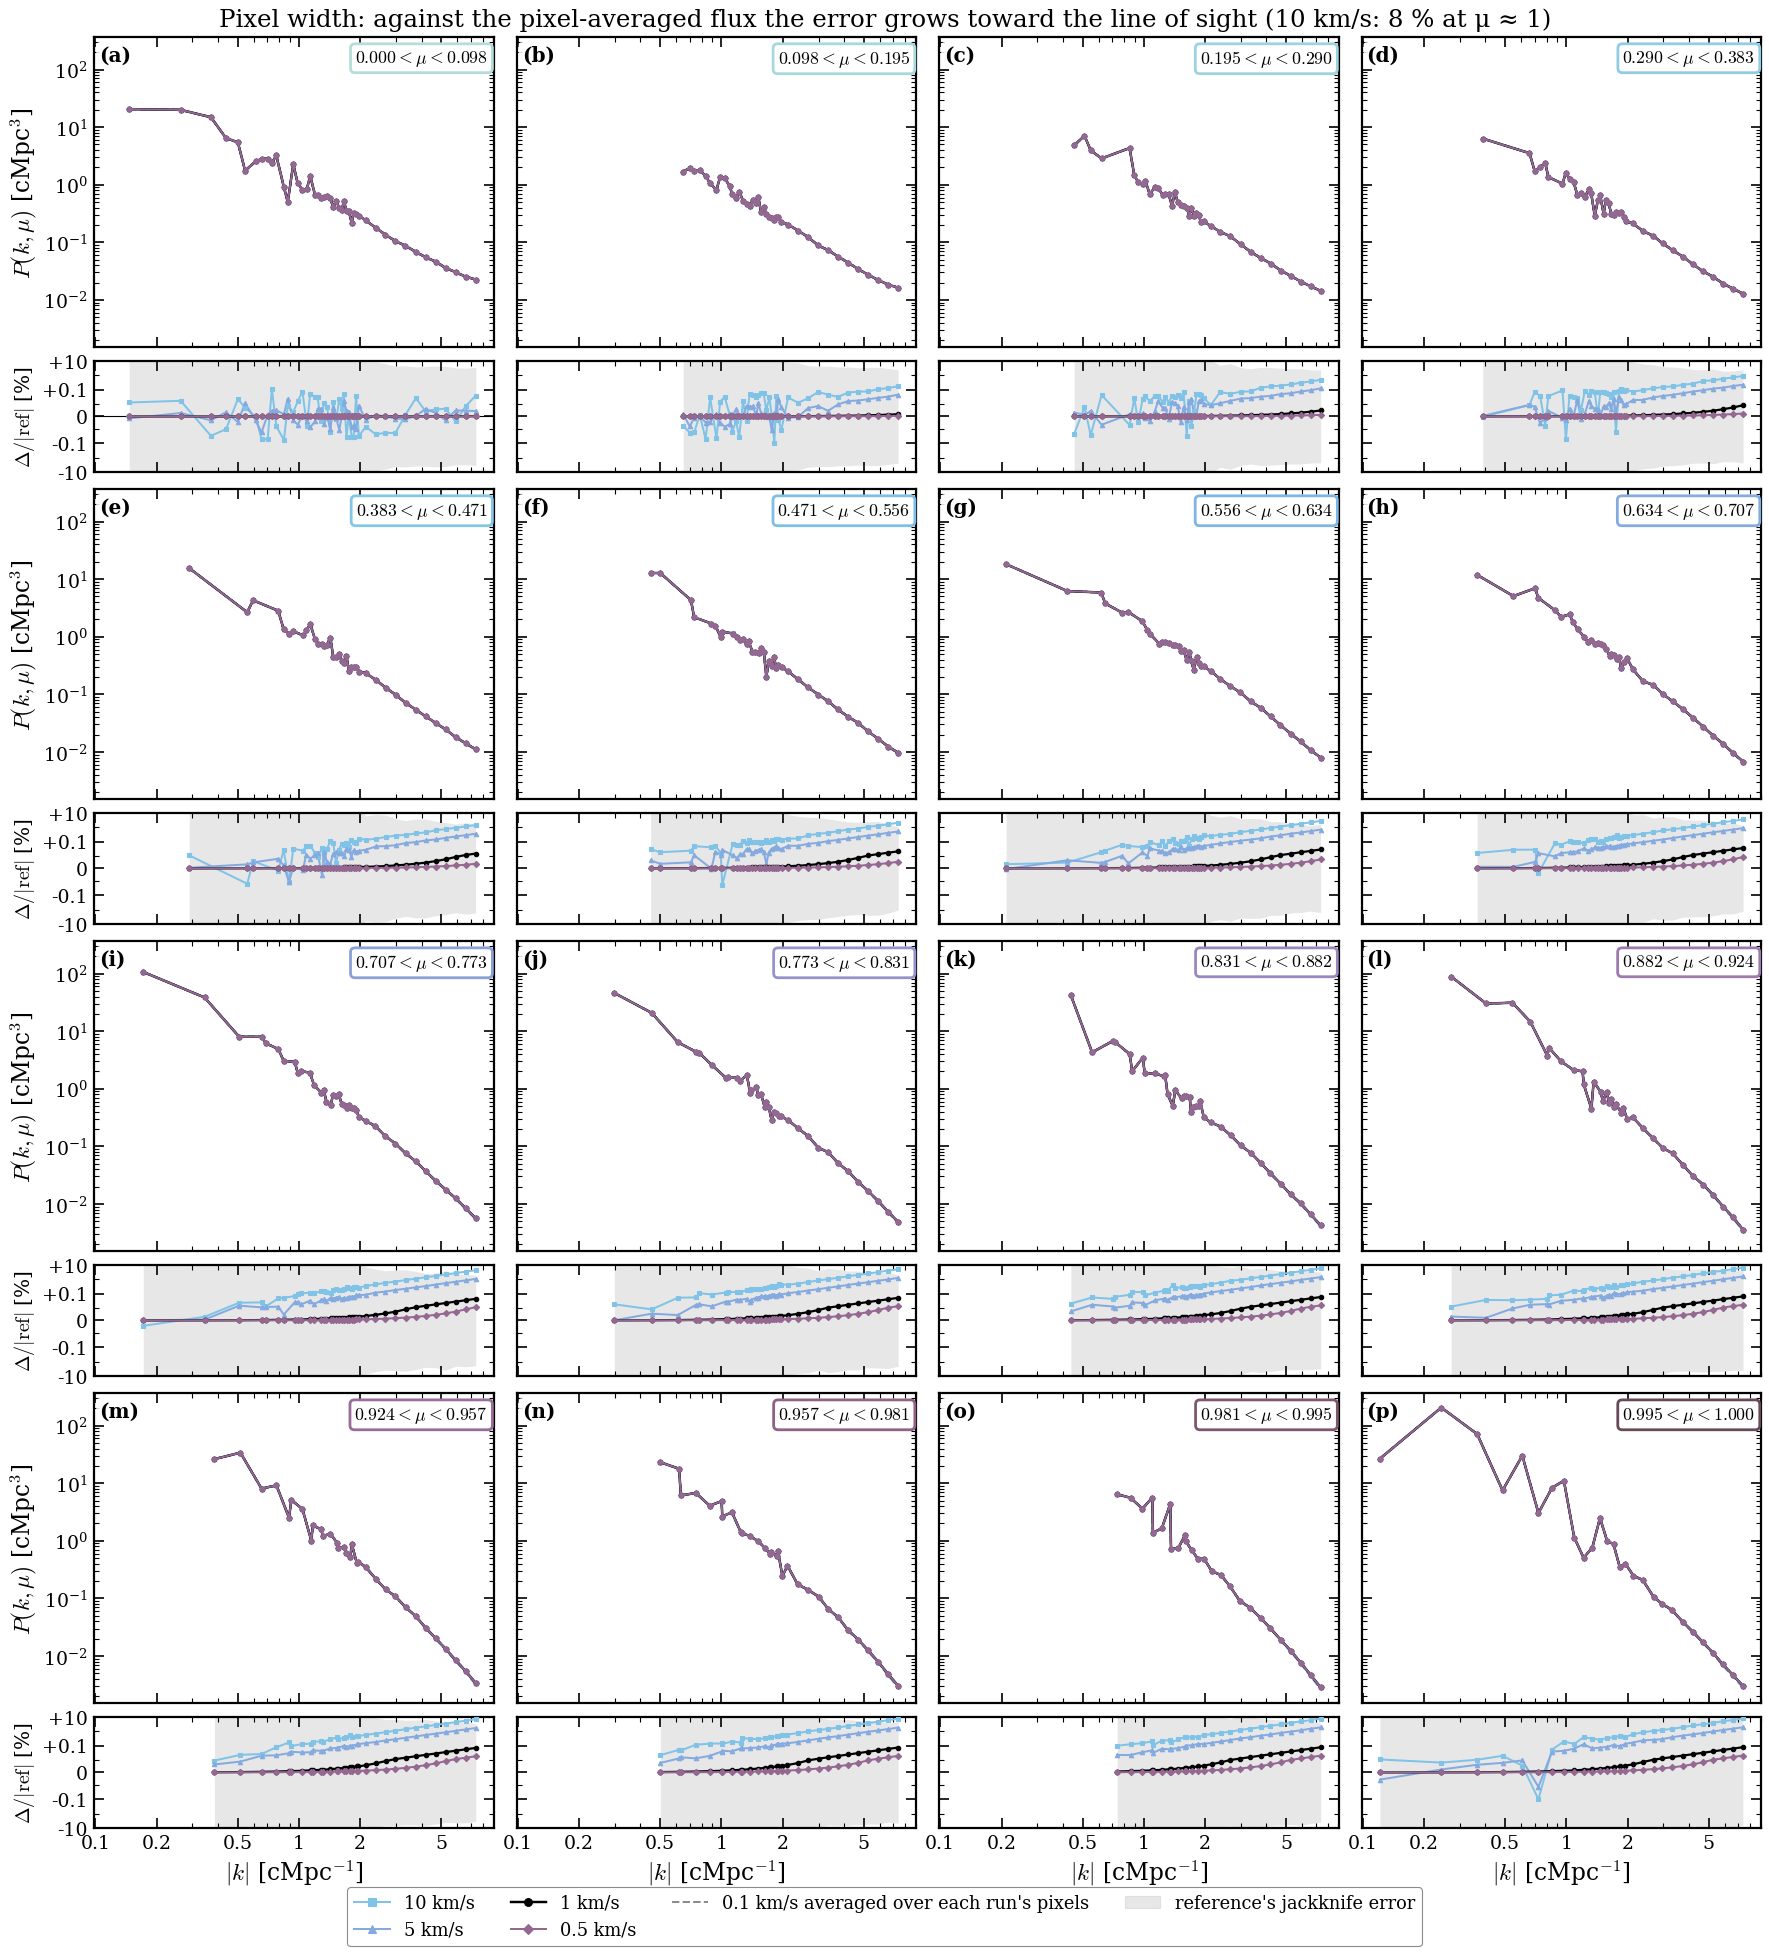

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dv_10kms       total                                 0.132          8.1        21.9       4%
dv_5kms        total                                0.0339         1.93        21.9       0%
dv_1kms        total                               0.00135       0.0771        21.9       0%
dv_0p5kms      total                              0.000351       0.0199        21.9       0%


In [7]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('total',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH, total_comparisons=CMP_REB,
                                        total_ref_label="0.1 km/s averaged over each run's pixels",
                                        titles={'total': "Pixel width: against the pixel-averaged flux the error grows toward the line of sight (10 km/s: 8 % at μ ≈ 1)"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_REB, ('total',), "P_mu"))

*Reading (total).* Against the 0.1 km/s flux averaged over each pixel (dashed, per run). The pixel window
acts along the line of sight only, so its missing factor grows with $\mu$: at 10 km/s the largest $|\Delta|$ climbs
steadily from 0.1% in the widest-angle wedge to 8% at $\mu \approx 1$ (5 km/s: 0.02% to 1.9%; 1 km/s: $\le 0.08$%).
Every difference stays inside the 20% jackknife error of the $128^2$ lattice.

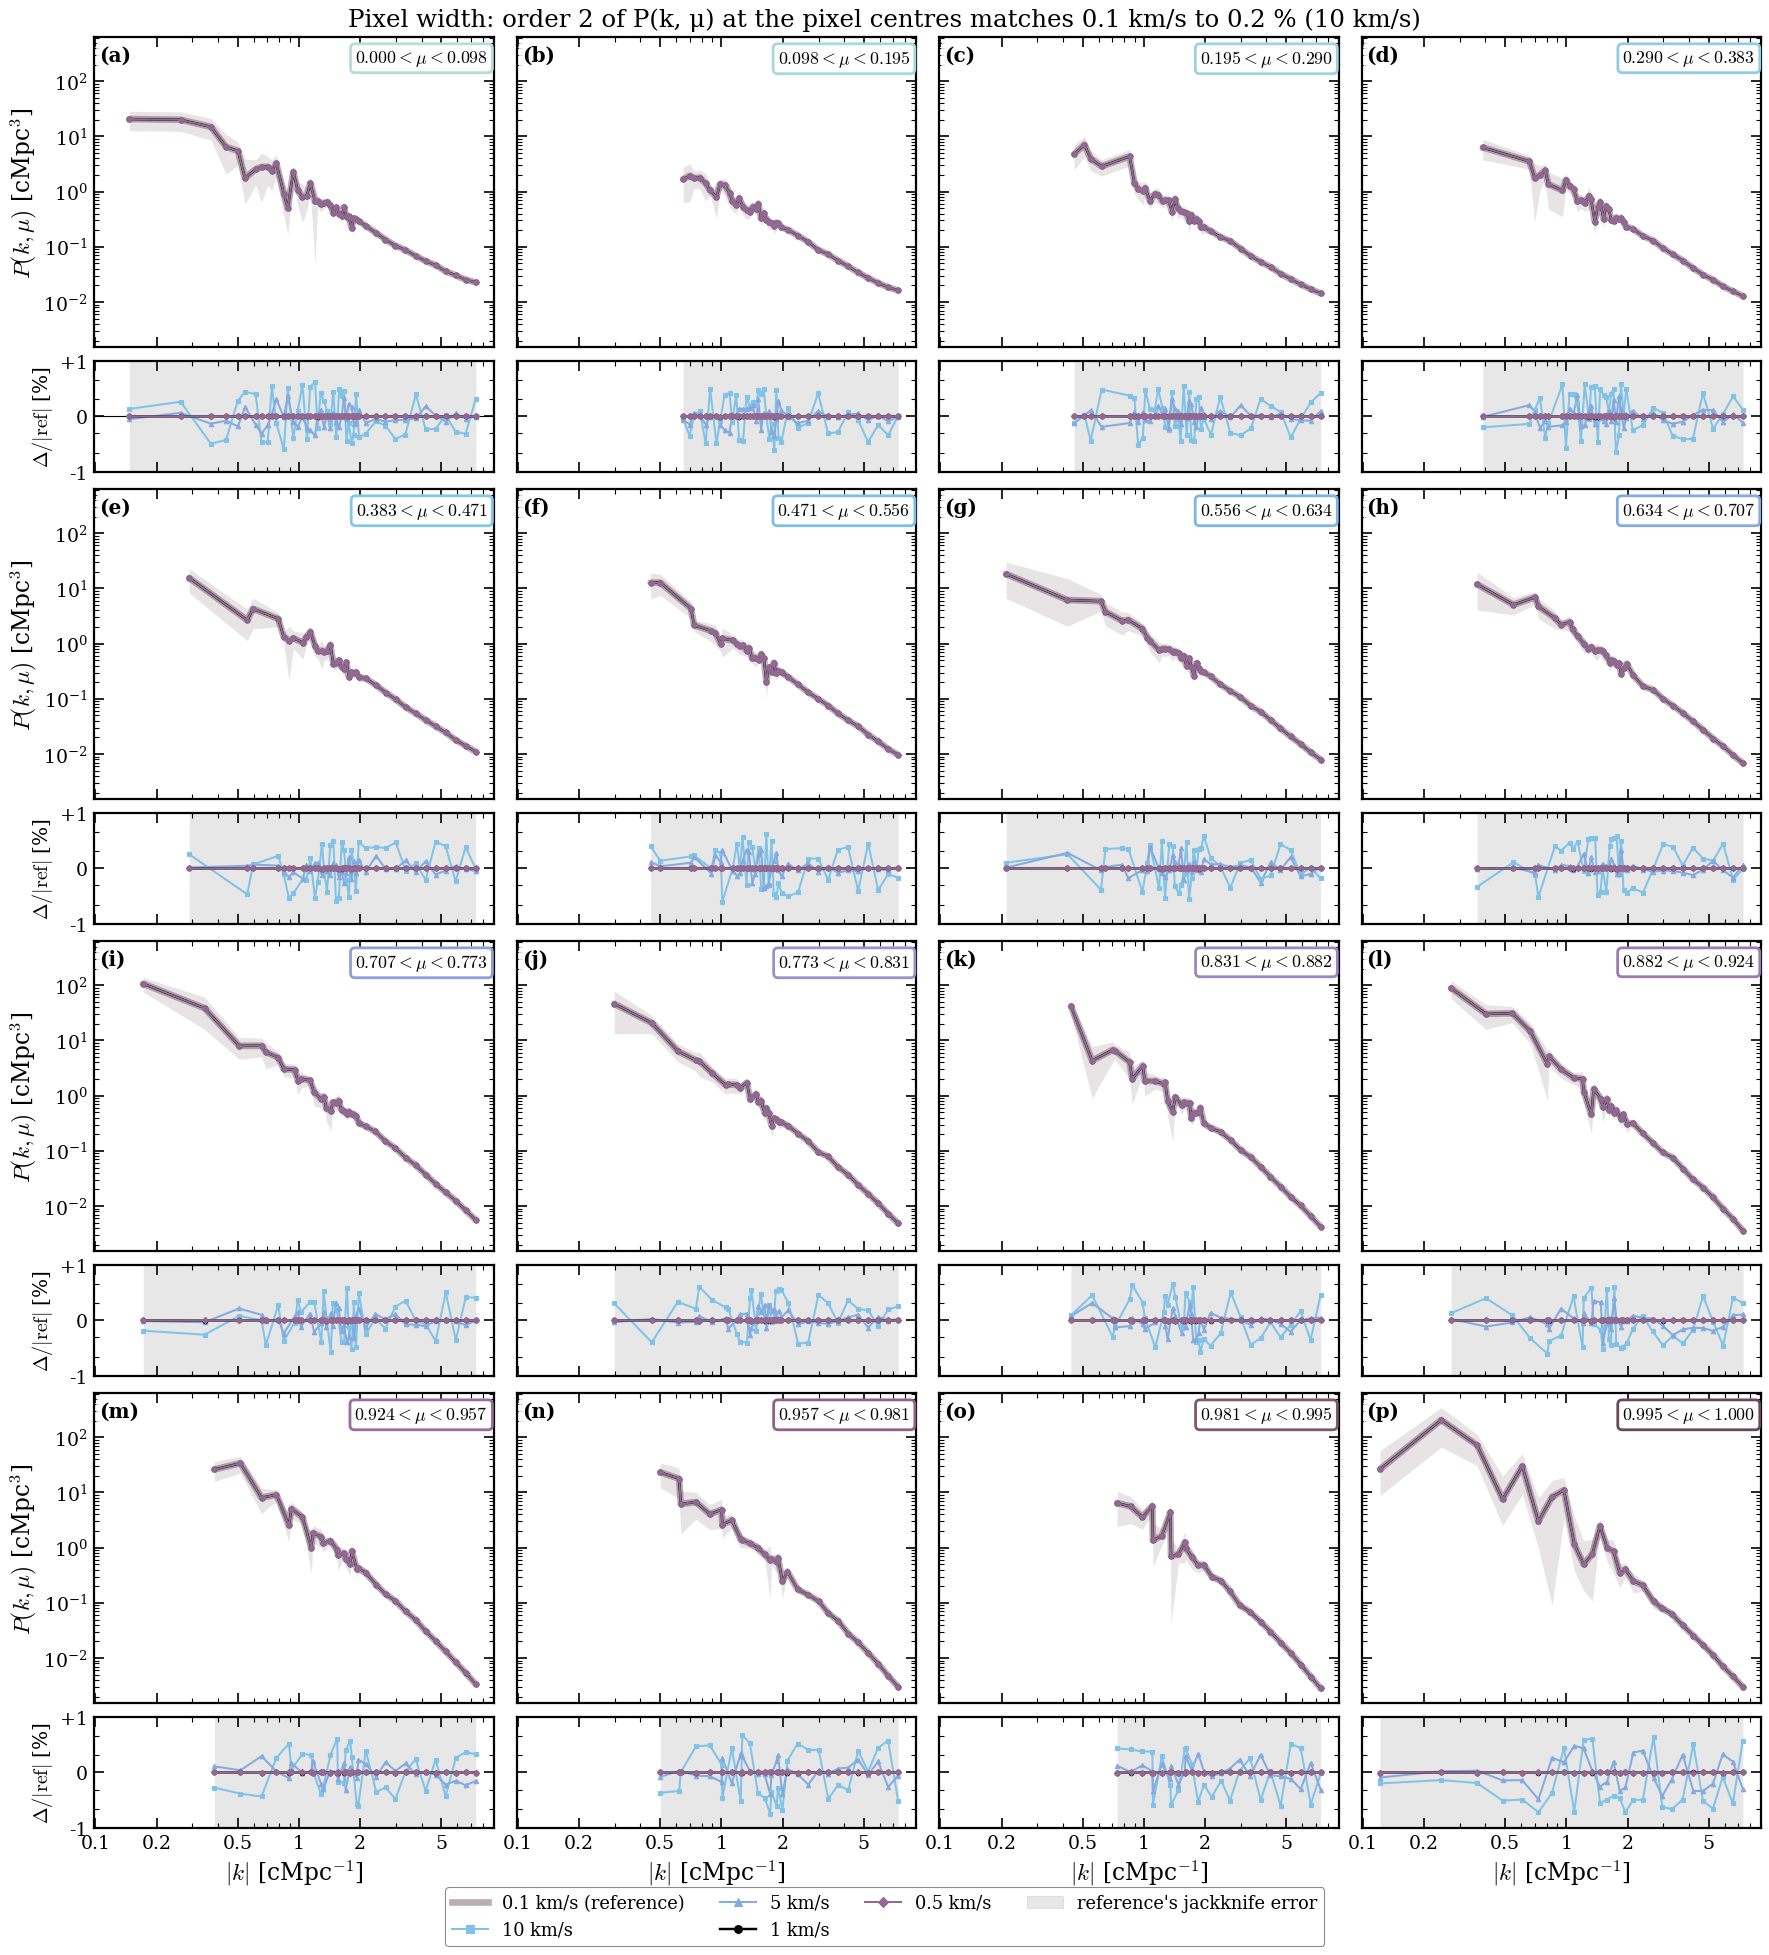

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dv_10kms       order 2                              0.0148        0.179          22       0%
dv_5kms        order 2                             0.00307       0.0328          22       0%
dv_1kms        order 2                            1.29e-05     0.000142          22       0%
dv_0p5kms      order 2                             1.1e-05     0.000152          22       0%


In [8]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 2',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 2': "Pixel width: order 2 of P(k, μ) at the pixel centres matches 0.1 km/s to 0.2 % (10 km/s)"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 2',), "P_mu"))

*Reading (order 2).* Against the 0.1 km/s run as it is: sampled at the pixel centres, order 2 (the
$\mathrm{Ly}\alpha$ auto, mostly) agrees to a median 0.015% and at most 0.18% at 10 km/s, $10^{-5}$% at 1 km/s.

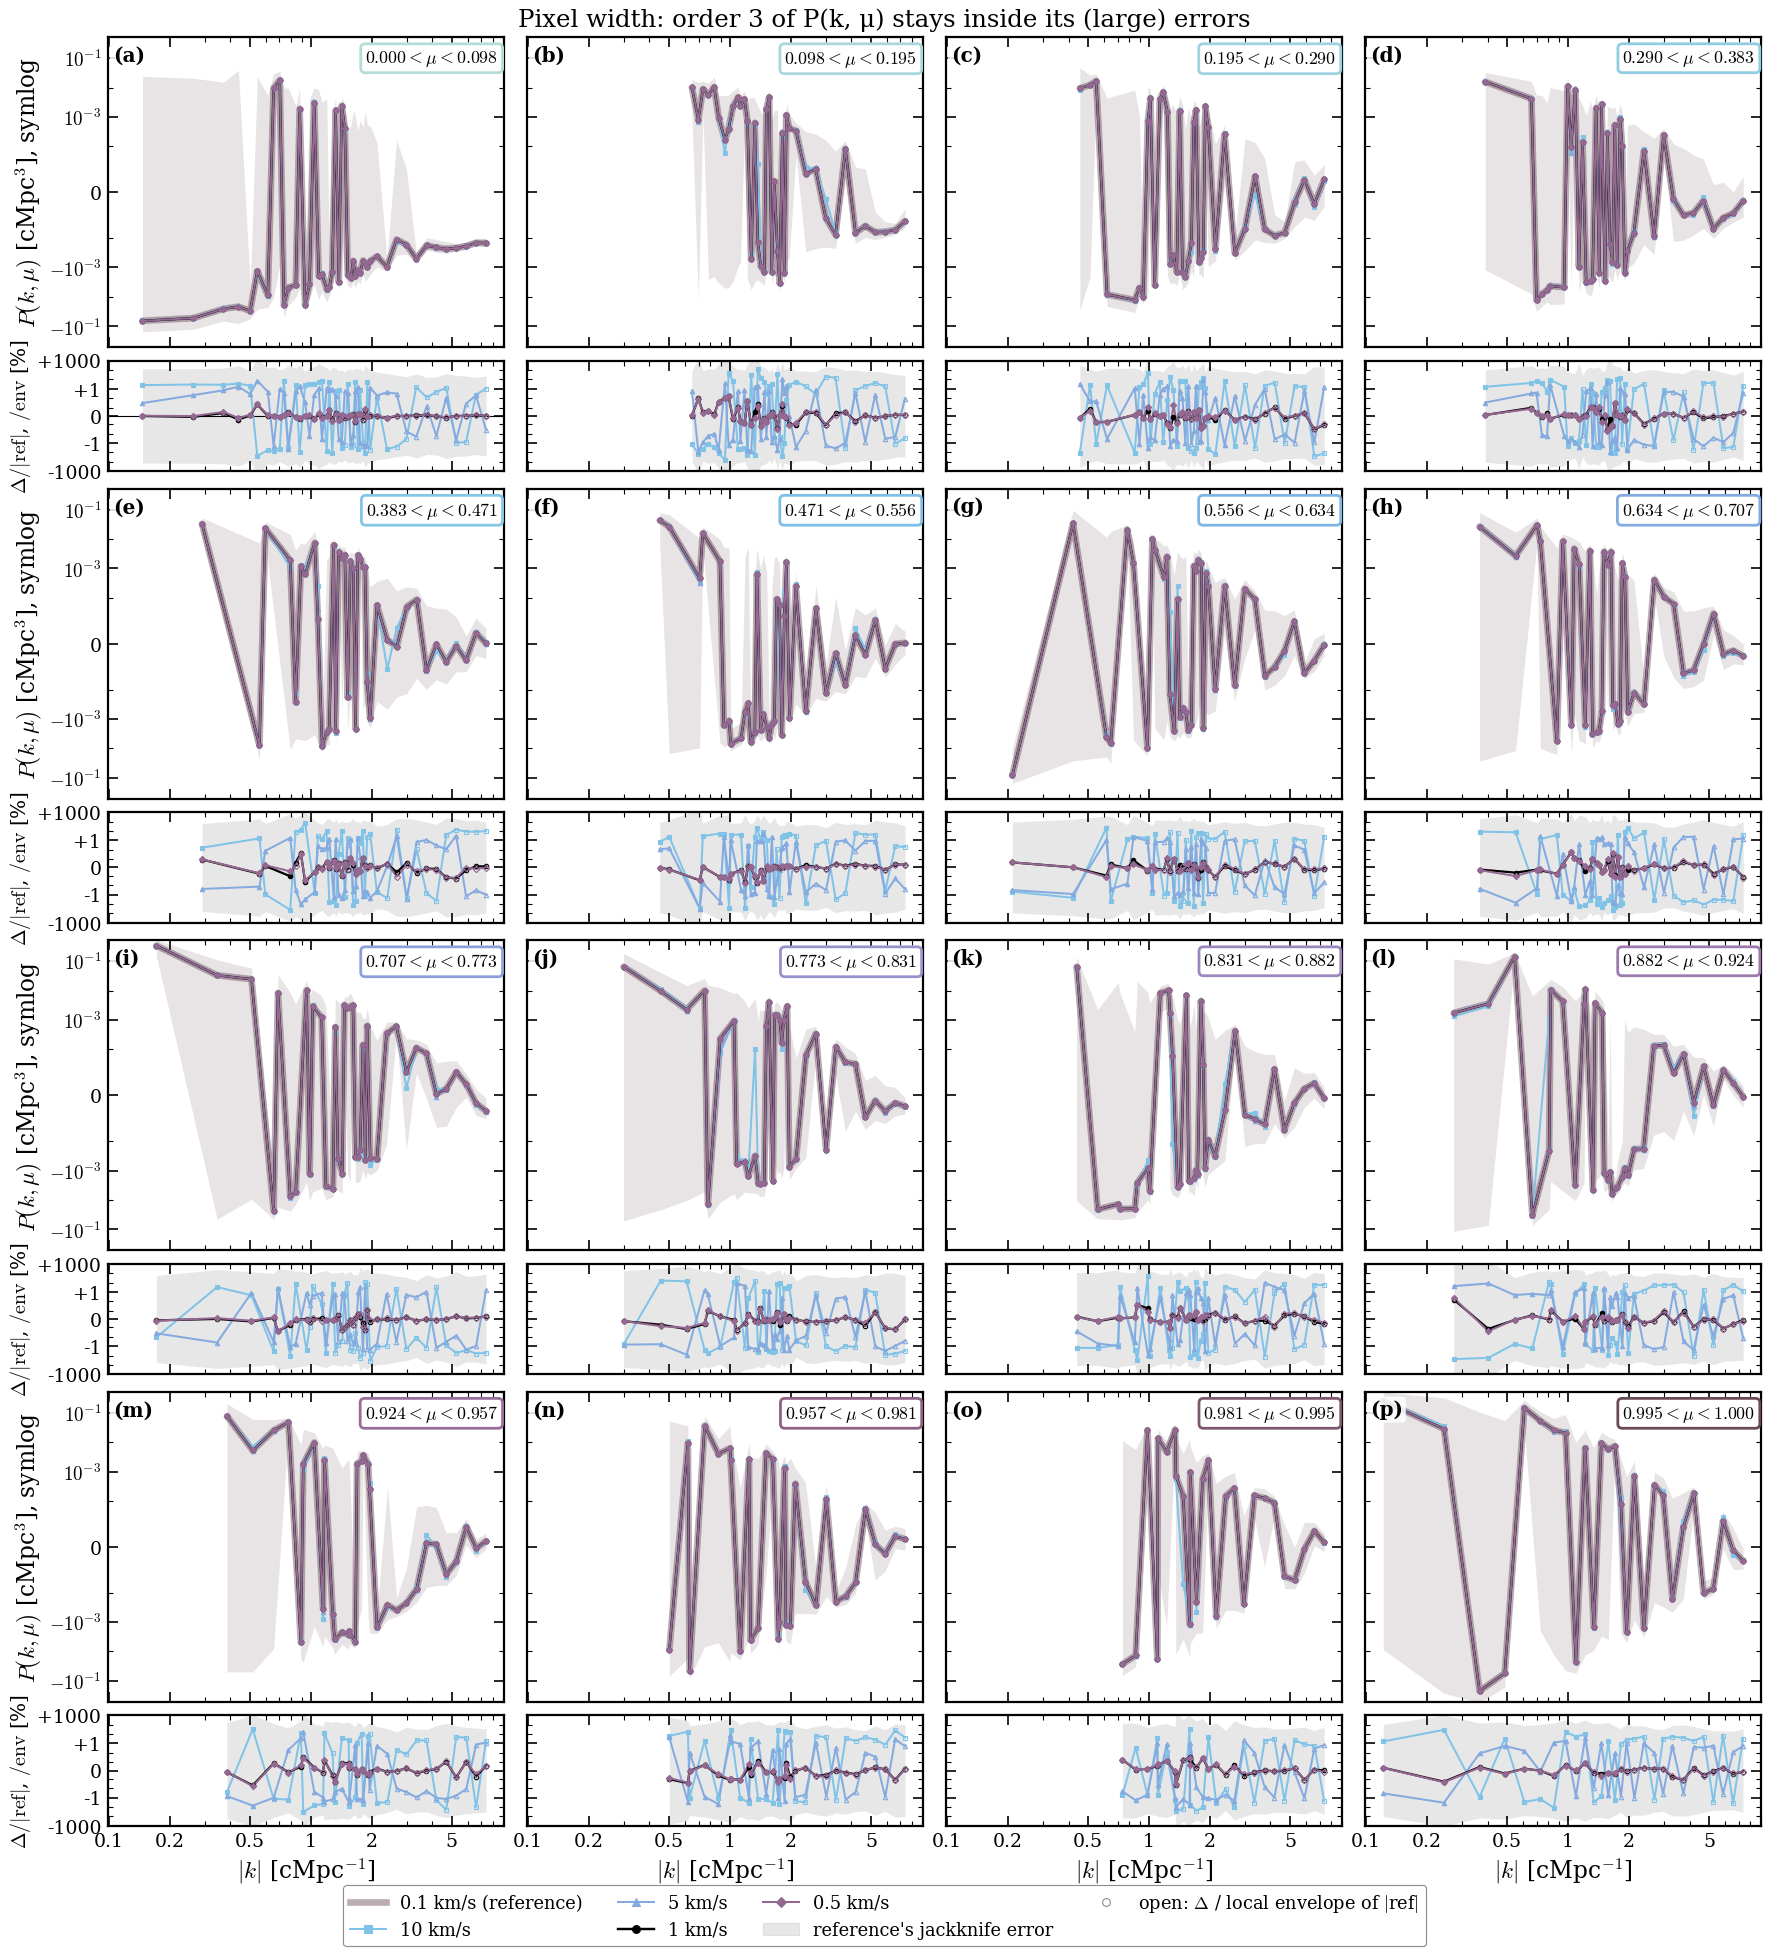

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dv_10kms       order 3                                3.13          119         110       0%
dv_5kms        order 3                               0.636         30.2         110       0%
dv_1kms        order 3                             0.00329         0.16         110       0%
dv_0p5kms      order 3                             0.00315        0.228         110       0%


In [9]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 3',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 3': "Pixel width: order 3 of P(k, μ) stays inside its (large) errors"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 3',), "P_mu"))

*Reading (order 3).* Order 3 is noise-dominated (error $\sim 110$% of its envelope); 10 km/s moves it by a median
3% of its envelope, every bin inside the band.

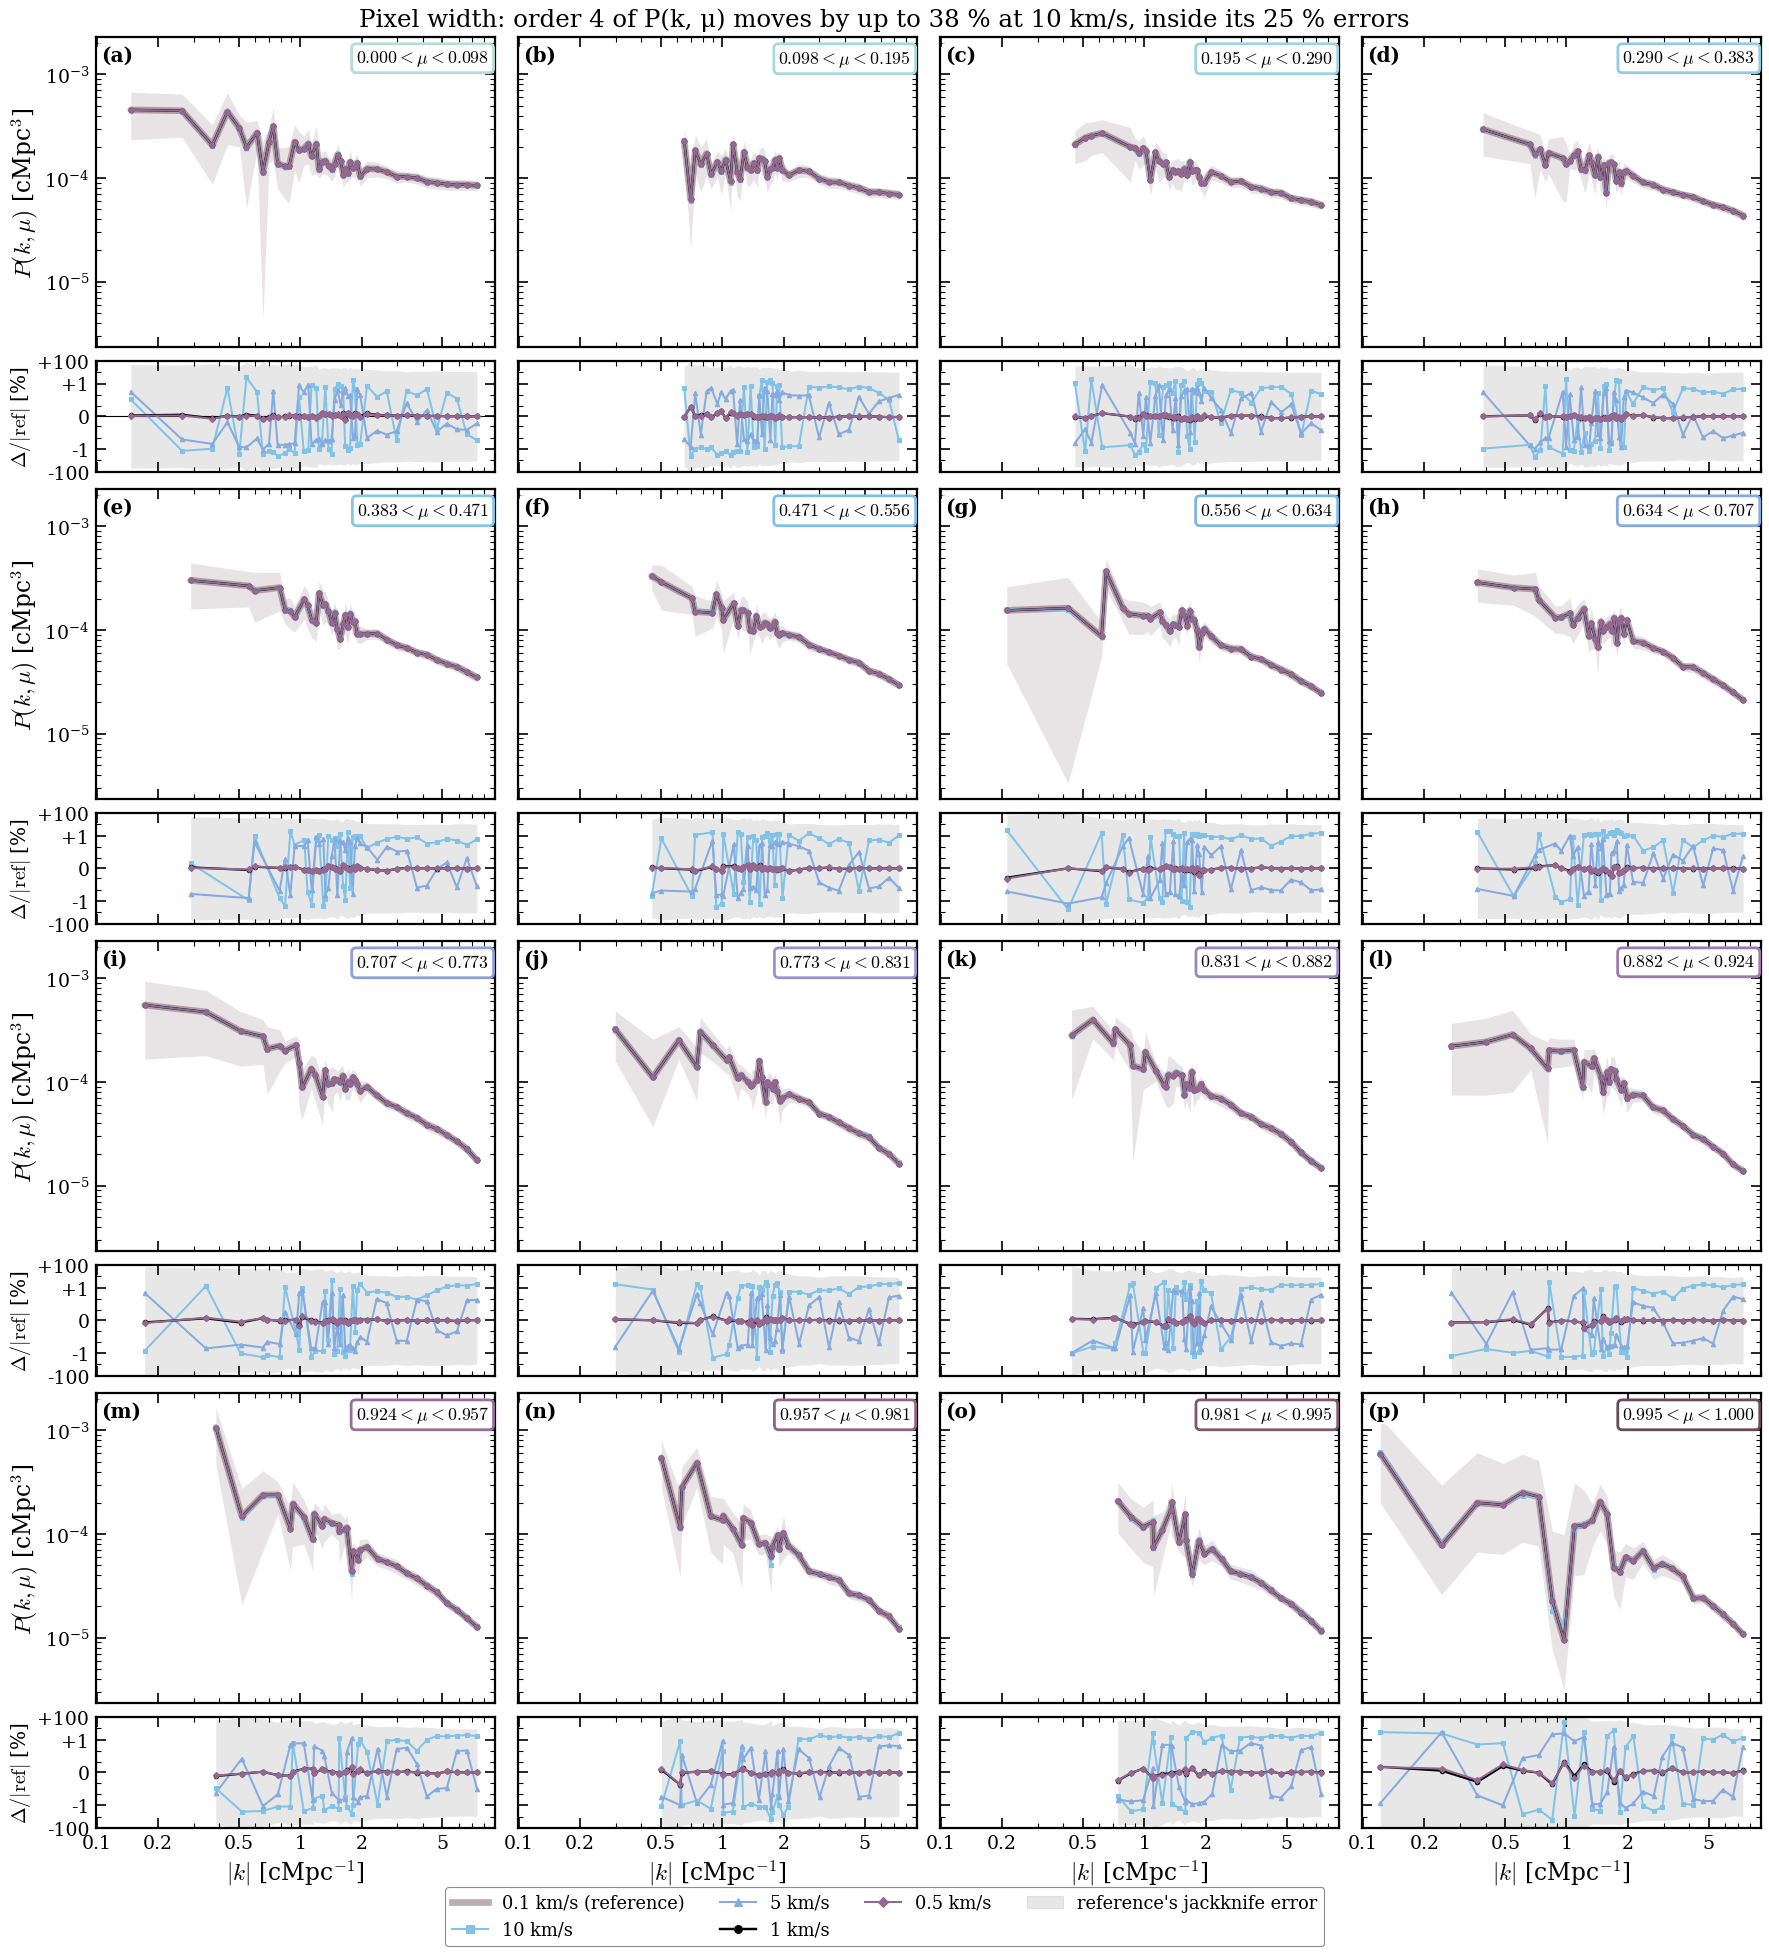

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dv_10kms       order 4                                0.93         38.2          25       0%
dv_5kms        order 4                               0.145         4.59          25       0%
dv_1kms        order 4                            0.000811       0.0152          25       0%
dv_0p5kms      order 4                            0.000802       0.0146          25       0%


In [10]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 4',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 4': "Pixel width: order 4 of P(k, μ) moves by up to 38 % at 10 km/s, inside its 25 % errors"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 4',), "P_mu"))

*Reading (order 4).* Order 4 reacts most among the orders: median 0.9%, up to 38% at 10 km/s (0.15% and 5% at
5 km/s), largest near the line of sight at high $|k|$; still inside its jackknife error.

### E2 · The wedges term by term (order 2)

One figure each for the $\mathrm{Ly}\alpha$ auto, the Si III auto and the cross term, against the 0.1 km/s run as it is.

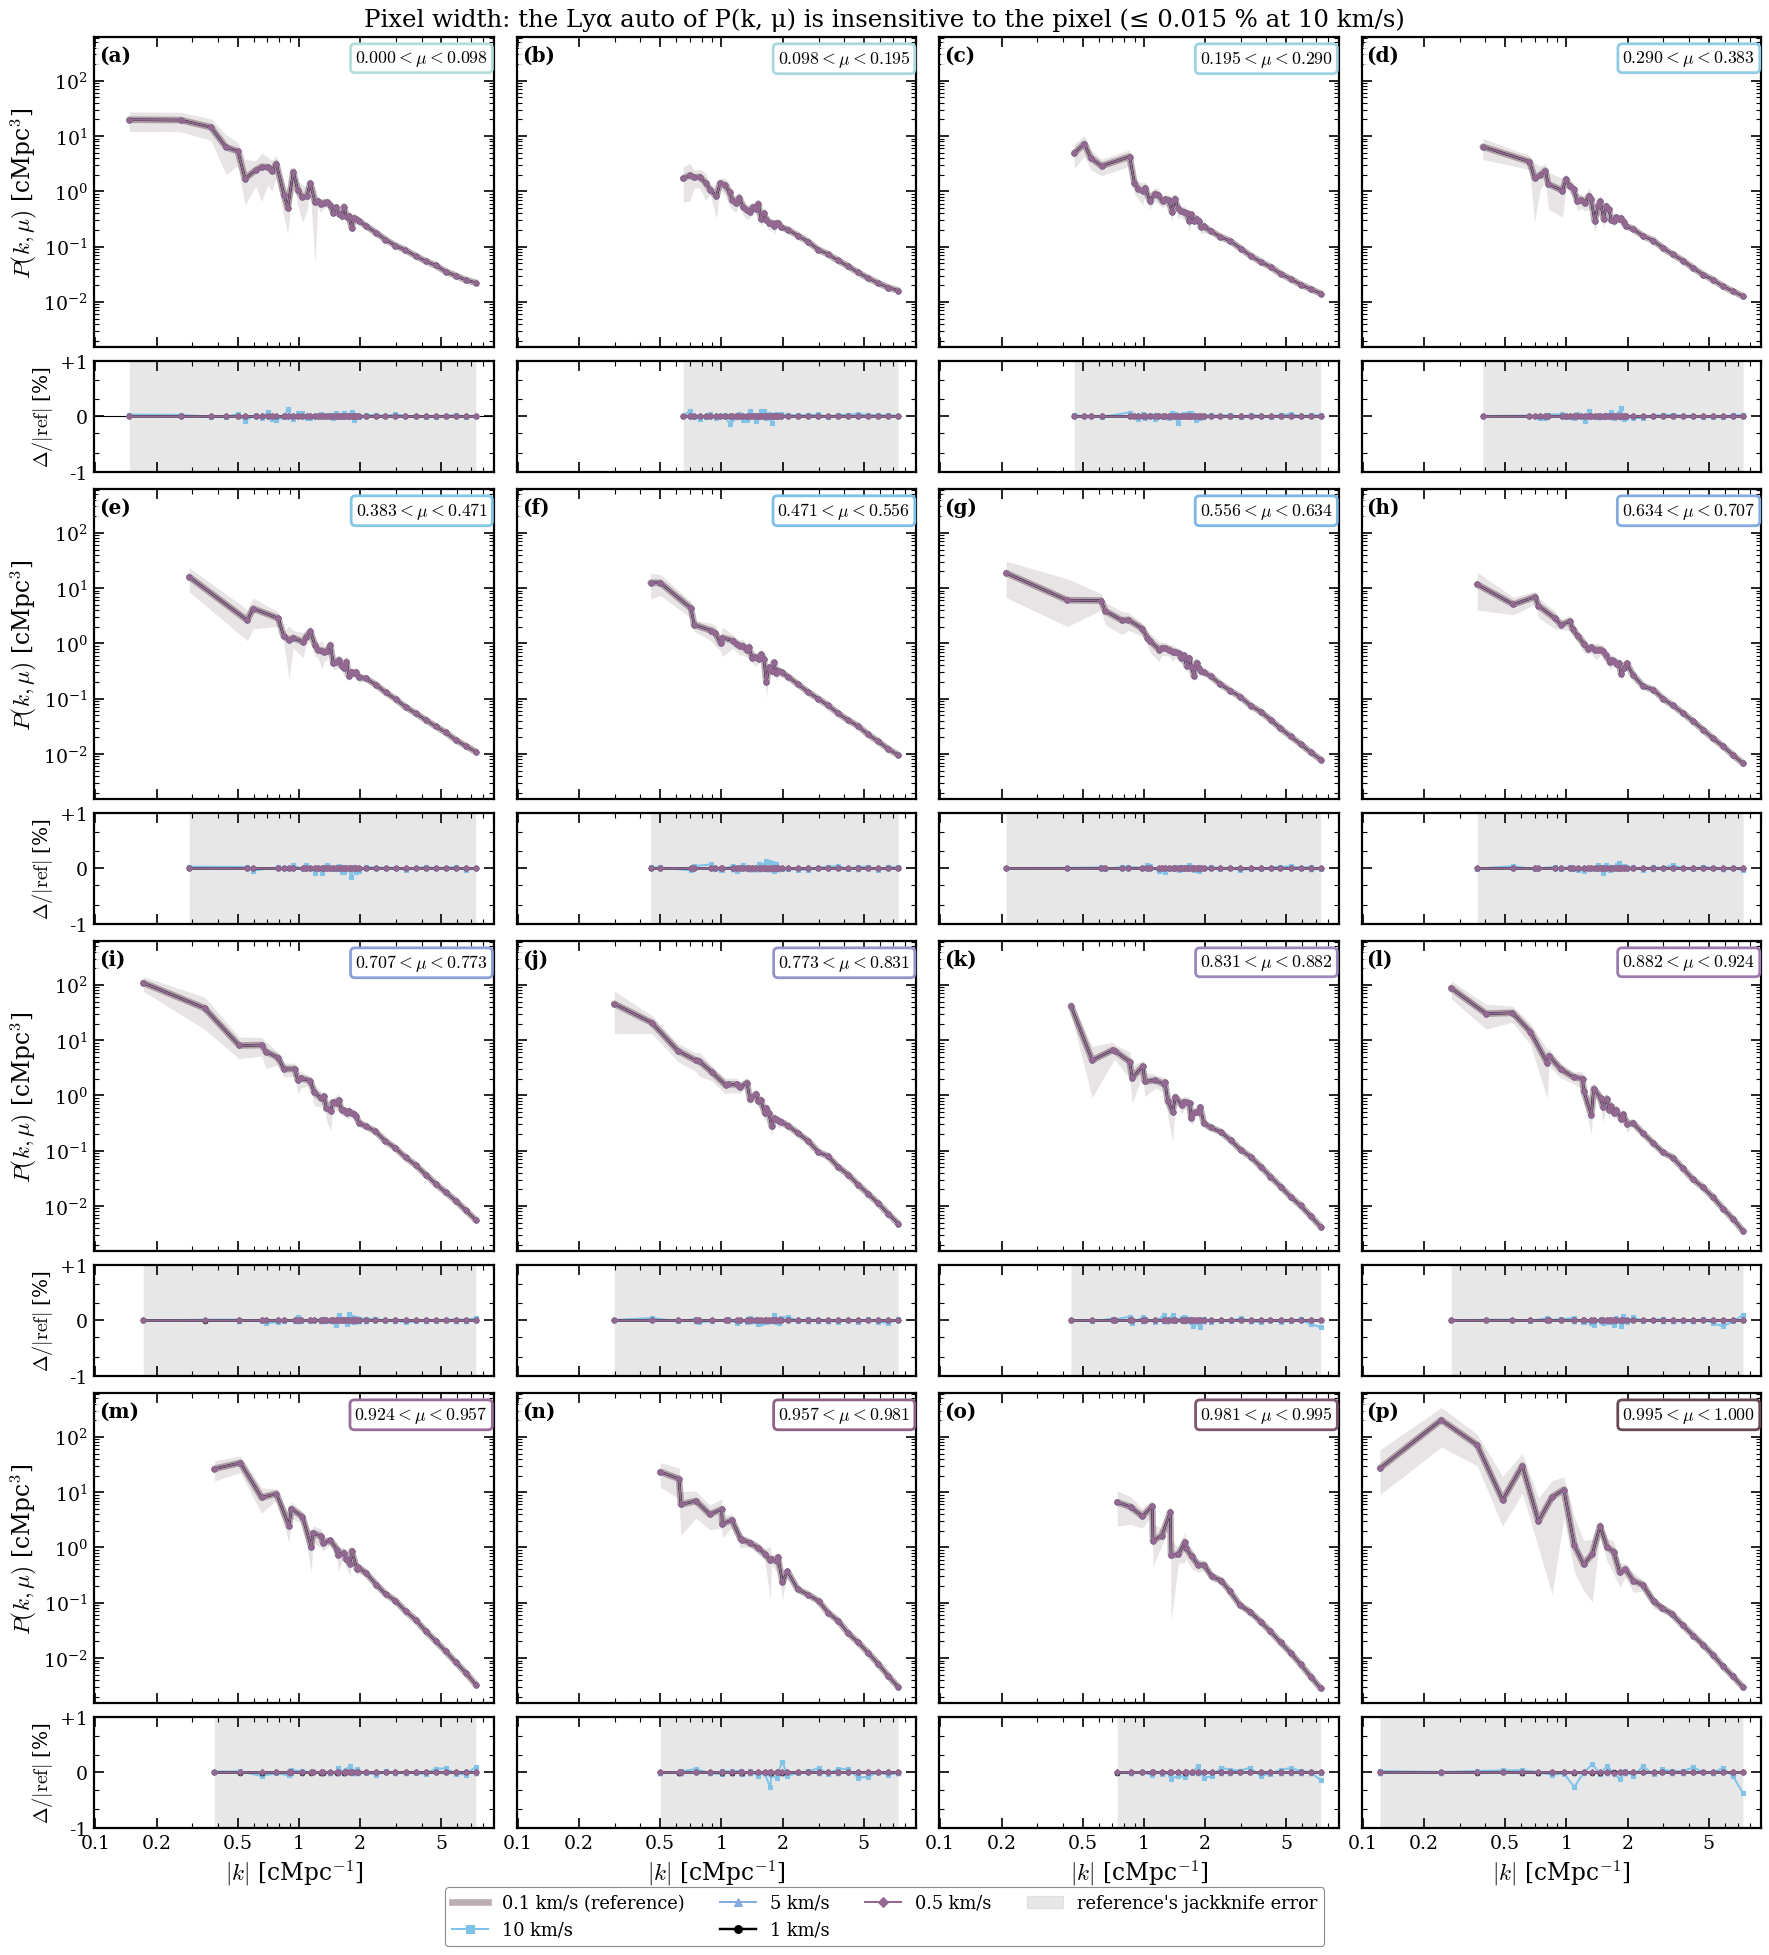

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dv_10kms       HI-LyA|HI-LyA                      0.000775       0.0151          22       0%
dv_5kms        HI-LyA|HI-LyA                      2.13e-05     0.000268          22       0%
dv_1kms        HI-LyA|HI-LyA                      7.66e-06     3.03e-05          22       0%
dv_0p5kms      HI-LyA|HI-LyA                      2.56e-06      2.7e-05          22       0%


In [11]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[0],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[0]: "Pixel width: the Lyα auto of P(k, μ) is insensitive to the pixel (≤ 0.015 % at 10 km/s)"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[0],), "P_mu"))

*Reading (term 1).* Median $8\times10^{-4}$%, at most 0.015% at 10 km/s: the broad $\mathrm{Ly}\alpha$ lines are well
sampled by any of these pixels.

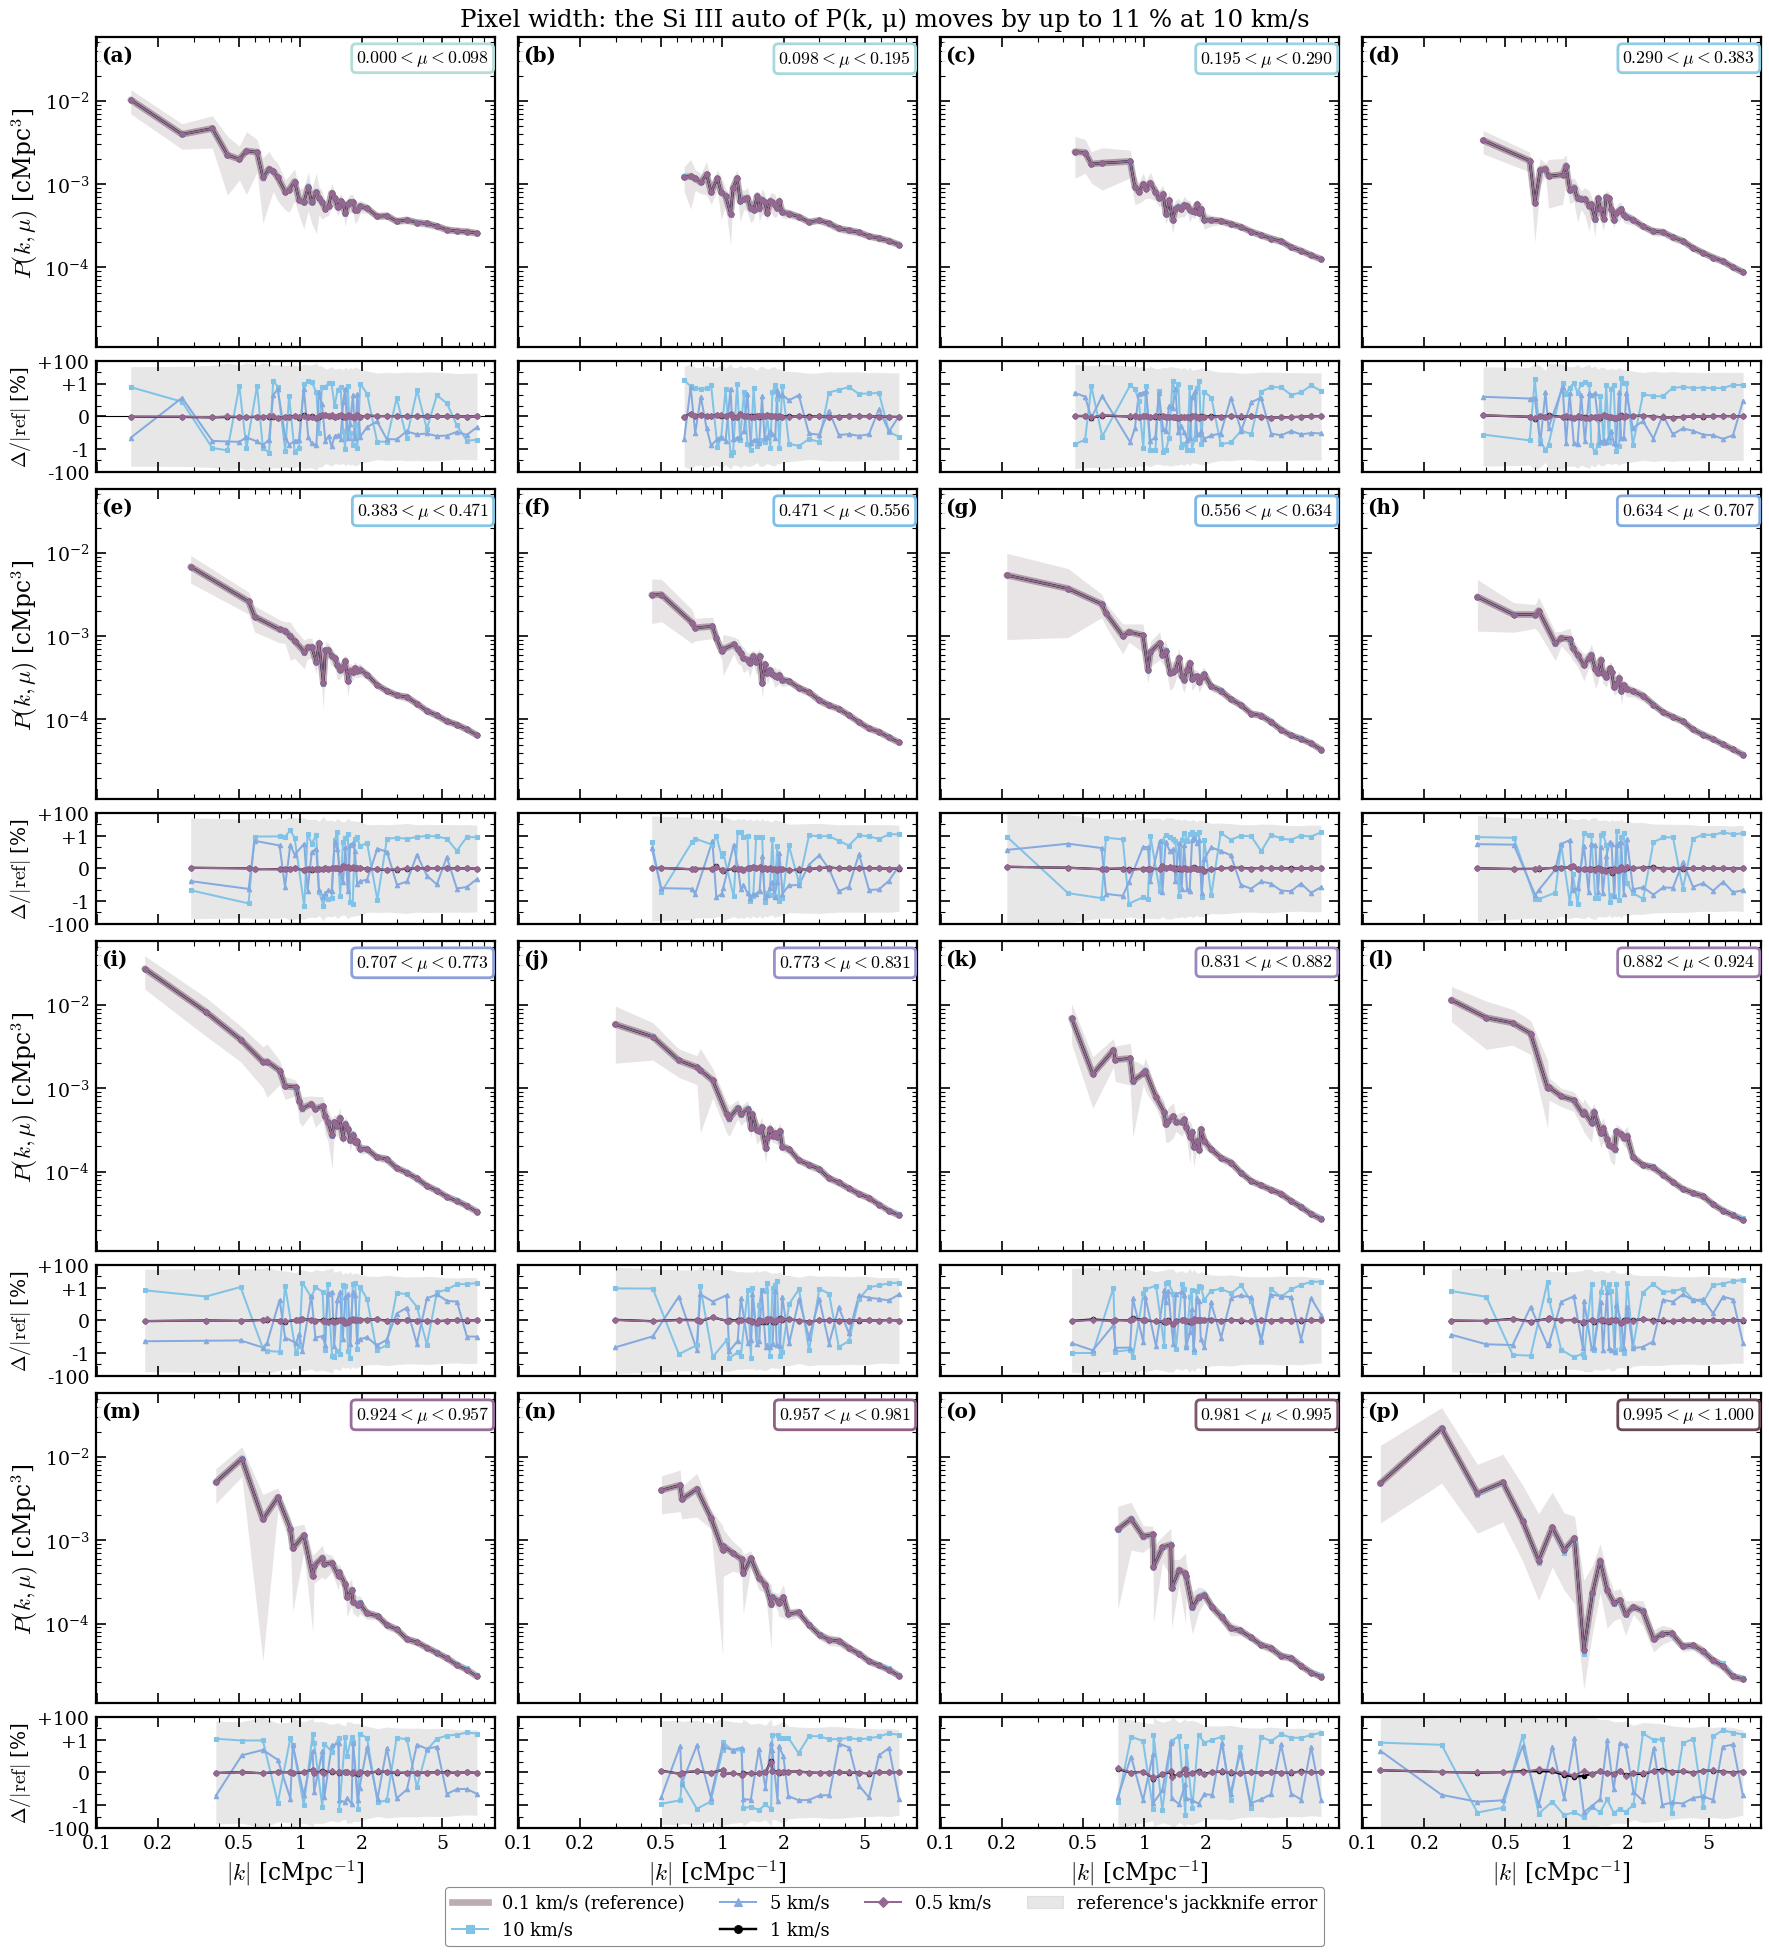

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dv_10kms       SiIII-1206|SiIII-1206                 0.726         11.3        23.5       0%
dv_5kms        SiIII-1206|SiIII-1206                 0.123         4.21        23.5       0%
dv_1kms        SiIII-1206|SiIII-1206              0.000473       0.0129        23.5       0%
dv_0p5kms      SiIII-1206|SiIII-1206              0.000459       0.0114        23.5       0%


In [12]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[1],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[1]: "Pixel width: the Si III auto of P(k, μ) moves by up to 11 % at 10 km/s"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[1],), "P_mu"))

*Reading (term 2).* The narrow Si III lines carry the pixel dependence: median 0.7%, up to 11% at 10 km/s, 4% at
5 km/s, $10^{-2}$% at 1 km/s; the residual changes sign from bin to bin (aliasing), inside the 23% error.

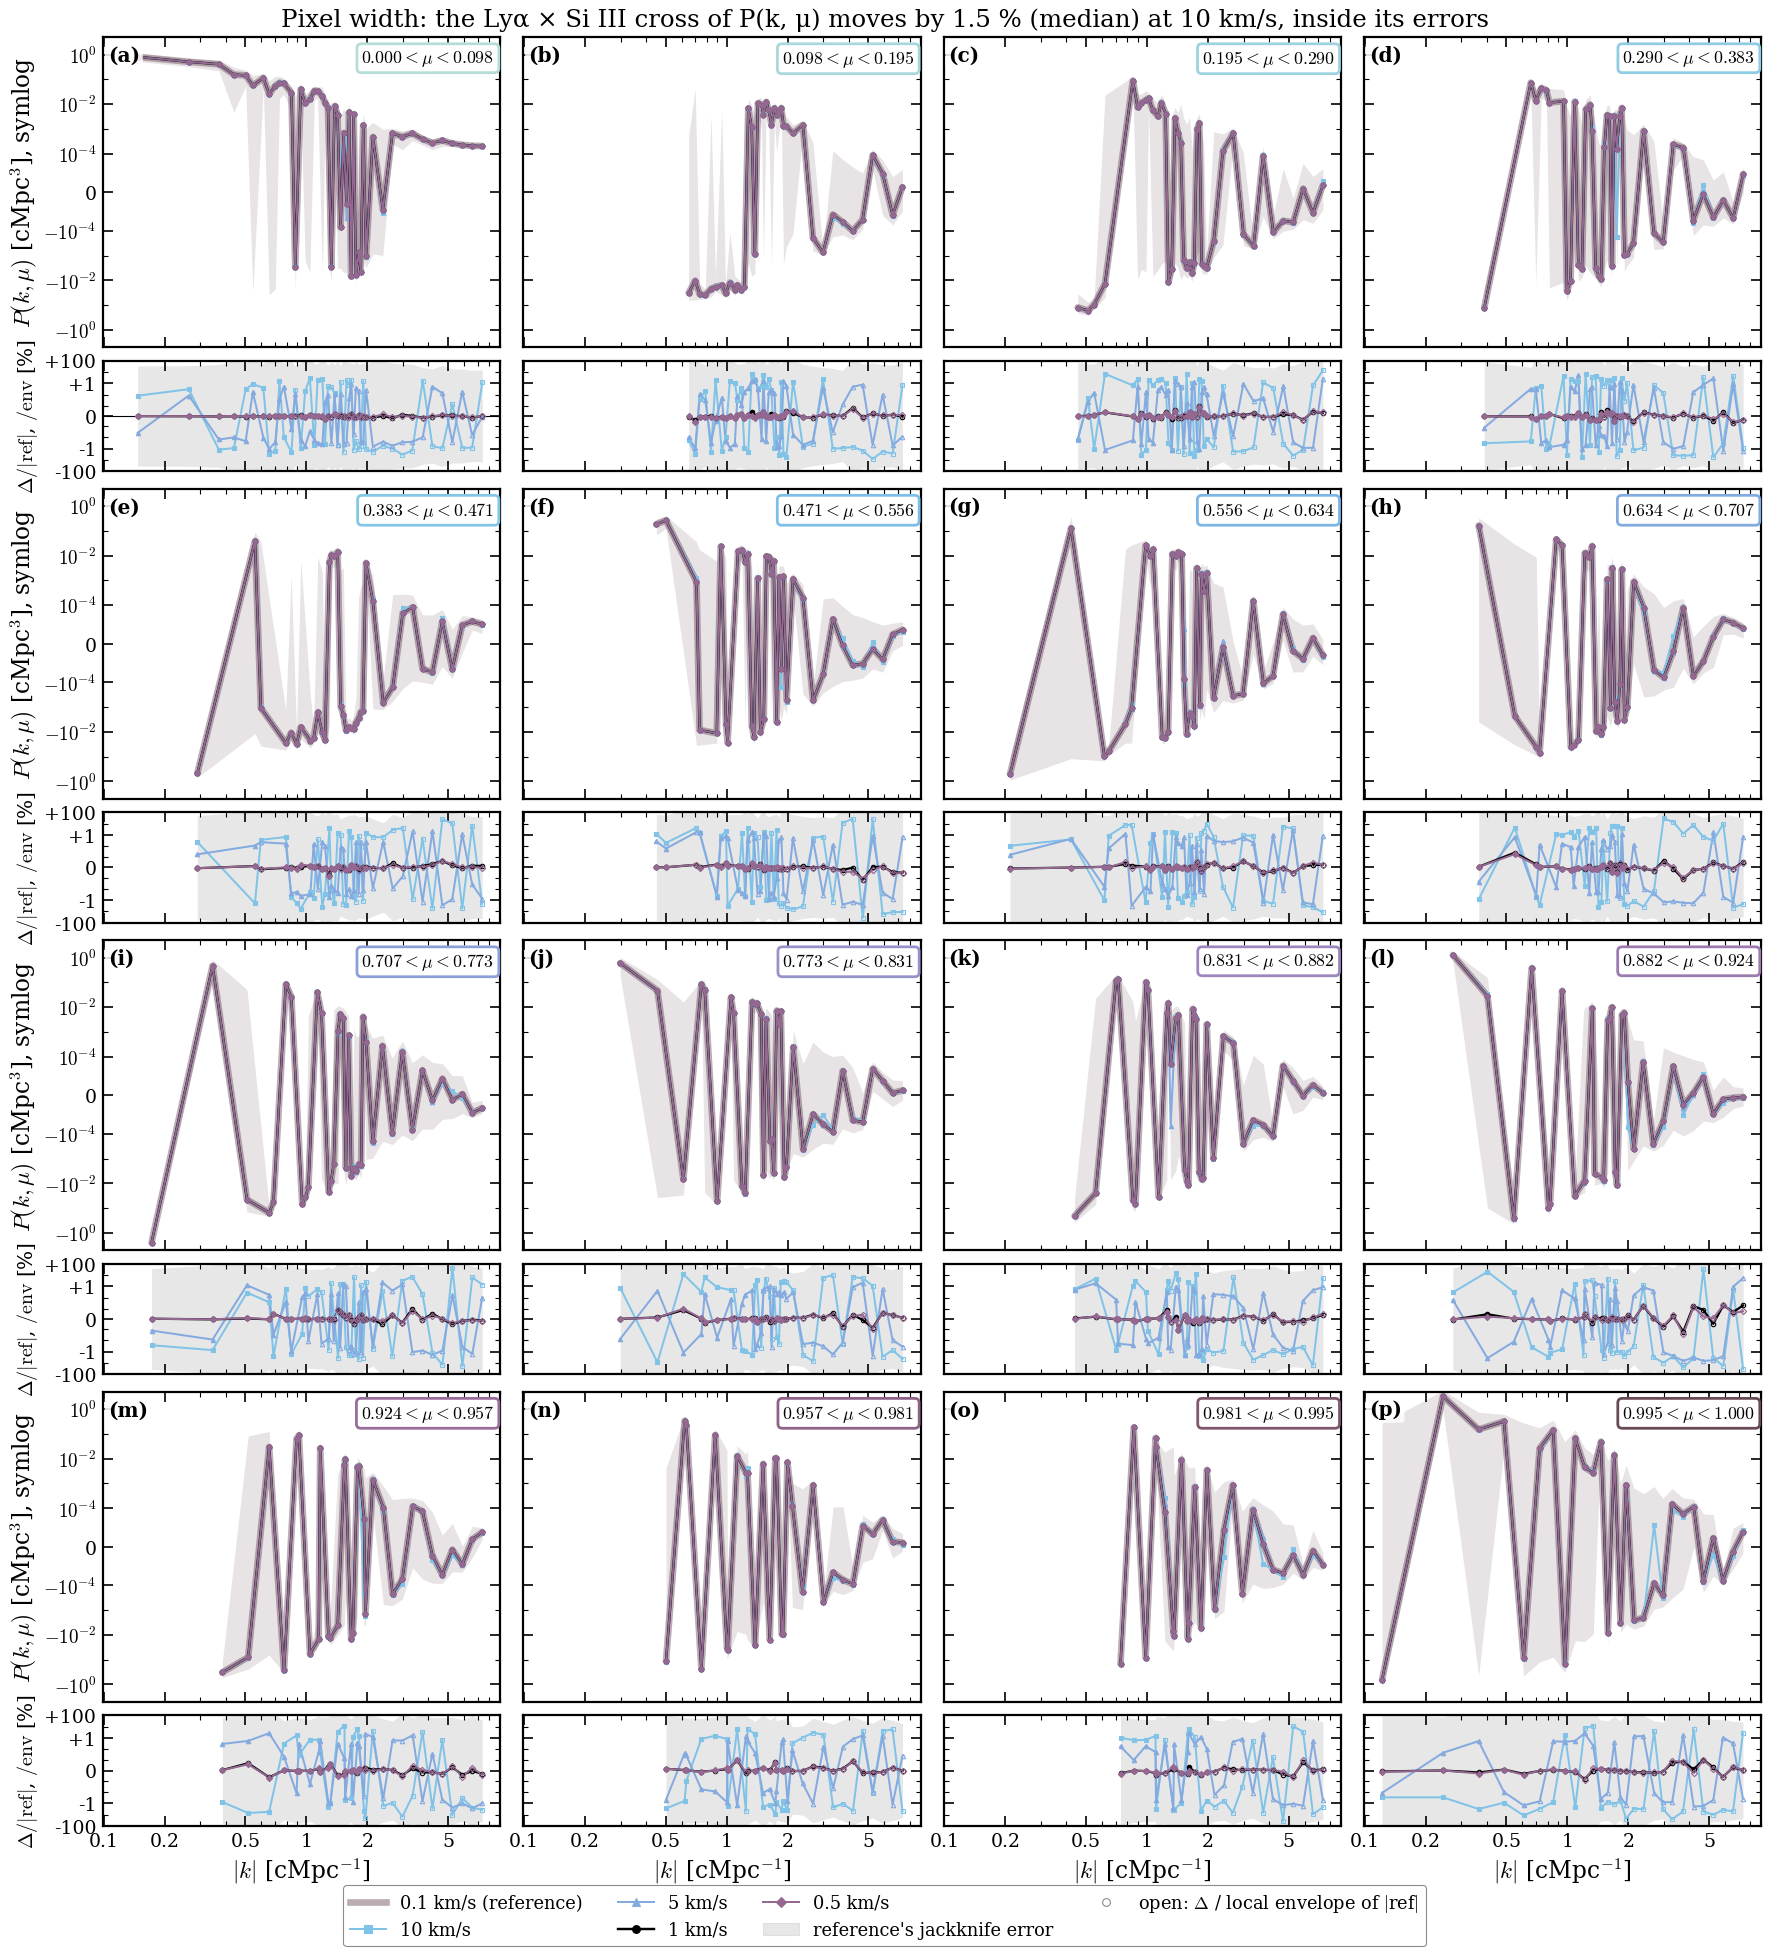

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
dv_10kms       HI-LyA|SiIII-1206                       1.5         44.1        67.3       0%
dv_5kms        HI-LyA|SiIII-1206                     0.304         6.51        67.3       0%
dv_1kms        HI-LyA|SiIII-1206                   0.00125       0.0266        67.3       0%
dv_0p5kms      HI-LyA|SiIII-1206                   0.00112       0.0283        67.3       0%


In [13]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[2],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[2]: "Pixel width: the Lyα × Si III cross of P(k, μ) moves by 1.5 % (median) at 10 km/s, inside its errors"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[2],), "P_mu"))

*Reading (term 3).* Relative to its local envelope the cross moves by a median 1.5% at 10 km/s (0.3% at 5 km/s),
inside a 67% error.

## Part F — The converged range

For every run and statistic, the largest $k$ up to which **every** bin differs from the reference by less than 0.1%,
0.5% and 1% (`k_max_table`: P1D on its native modes, $P(k, \mu)$ on its $|k|$ bins; "$\geq k$" when every bin passes up to
the run's last one; 0 when the first bin already fails). The last columns give the run's last bin and the median
jackknife error of the relative difference: a $k_{\max}$ set by bins whose difference is within that error is limited
by noise, not by the parameter. The figure draws $k_{\max}(0.5\%)$ against the pixel width.


The table is given twice: against the 0.1 km/s run and against its transmission averaged over each coarse pixel.

against dv_0p1kms; P1D on its native modes [s/km], P(k, mu) on its |k| bins [1/cMpc]; '>= k': every bin passes up to the run's last one; the DESI DR1 P1D reaches k = 0.032 s/km at z = 3.0
run            statistic                         k_max(0.1%)    k_max(0.5%)      k_max(1%)  last bin jk err [%]  unit
dv_10kms       P1D HI-LyA                              0.191           0.22          0.234     0.313      0.012  s/km
dv_10kms       P1D SiIII-1206                         0.0143         0.0207          0.043     0.313       0.91  s/km
dv_10kms       P1D total                               0.103          0.151          0.169     0.313        0.1  s/km
dv_10kms       P(k, mu) total mu 0.00-0.50           >= 7.38        >= 7.38        >= 7.38      7.38      0.018  1/cMpc
dv_10kms       P(k, mu) total mu 0.50-0.80           >= 7.38        >= 7.38        >= 7.38      7.38      0.018  1/cMpc
dv_10kms       P(k, mu) total mu 0.80-0.95           >= 7.38        >= 7.38        >= 7.38      7.38

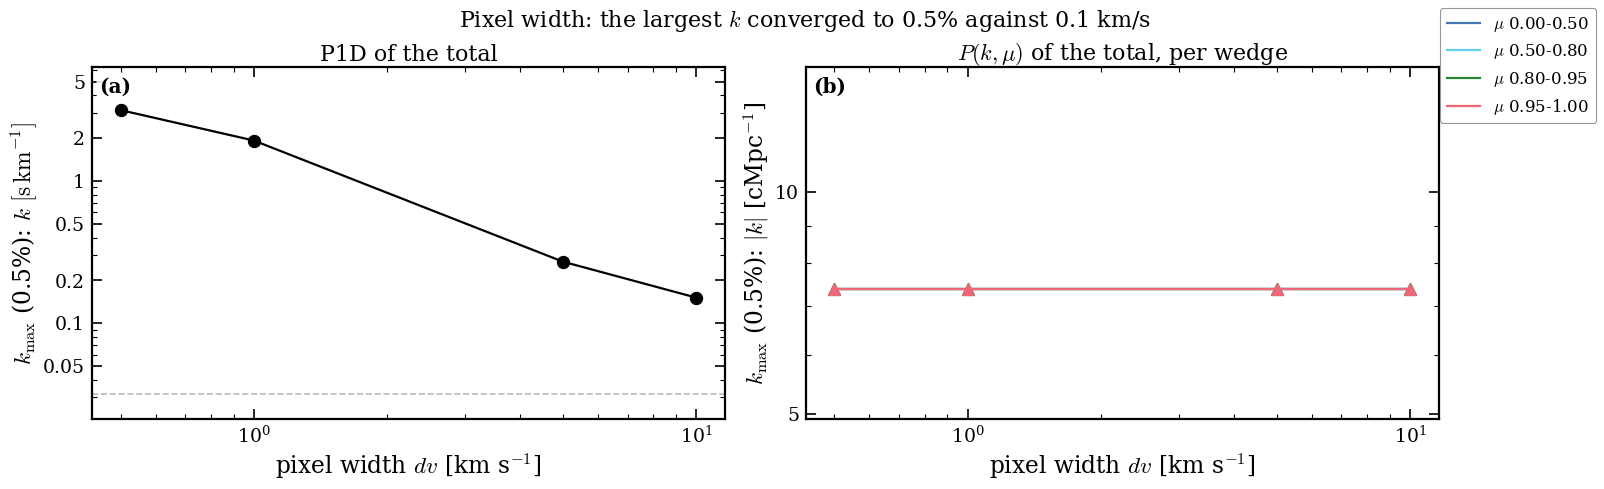


against the 0.1 km/s transmission averaged over each pixel:
run            statistic                         k_max(0.1%)    k_max(0.5%)      k_max(1%)  last bin jk err [%]  unit
dv_10kms       P1D HI-LyA                            0.00954         0.0239         0.0334     0.313       0.01  s/km
dv_10kms       P1D SiIII-1206                        0.00954         0.0143         0.0223     0.313       0.78  s/km
dv_10kms       P1D total                             0.00954         0.0239         0.0334     0.313      0.098  s/km
dv_10kms       P(k, mu) total mu 0.00-0.50              2.67           6.59        >= 7.38      7.38      0.018  1/cMpc
dv_10kms       P(k, mu) total mu 0.50-0.80              1.19           2.66           3.74      7.38      0.018  1/cMpc
dv_10kms       P(k, mu) total mu 0.80-0.95             0.938           2.13           2.98      7.38      0.018  1/cMpc
dv_10kms       P(k, mu) total mu 0.95-1.00             0.743           1.86           2.66      7.38      0

In [14]:
ROWS = k_max_table(CMP_ALL, TOLS)
print(f"against {REFERENCE}; P1D on its native modes [s/km], P(k, mu) on its |k| bins [1/cMpc]; '>= k': every bin passes "
      f"up to the run's last one; the DESI DR1 P1D reaches k = {K_DESI:.3f} s/km at z = {P1D_REF['z']}")
print(format_k_max_table(ROWS, TOLS))
fig, axs = plot_k_max_summary(ROWS, X_OF_RUN, xlabel=X_LABEL, xscale=X_SCALE, xticks=X_TICKS, tol=0.005, p1d_k_ref=K_DESI,
                              title=f"{TITLE_STEM}: the largest $k$ converged to 0.5% against {RUN_LABELS[REFERENCE]}")
add_panel_letters(axs)
plt.show()

print("\nagainst the 0.1 km/s transmission averaged over each pixel:")
print(format_k_max_table(k_max_table(CMP_REB_ALL, TOLS), TOLS))

**Reading.** The answer depends on the reference: the 0.1 km/s run itself, or its flux averaged over each pixel.

* **Against the 0.1 km/s run** (a coarse run samples the same $\tau$ at its pixel centres):
  * the mean transmission agrees to $2\times10^{-6}$ or better;
  * $P_\mathrm{1D}$ of $\mathrm{Ly}\alpha$ is within 0.5% up to $k$ = 0.22, 0.48, 1.4 and 2.5 s/km at 10, 5, 1 and 0.5 km/s, so
    every width covers the DESI DR1 range;
  * the excess near each grid's Nyquist frequency is aliasing (the power above it folded back);
  * Si III departs first, at 10 km/s from 0.021 s/km: its lines are narrower;
  * $P(k, \mu)$ agrees everywhere up to 7.4 cMpc$^{-1}$, the transverse limit of the $128^2$ lattice.
* **Against the 0.1 km/s flux averaged over each coarse pixel** (what a spectrograph with that pixel records), the coarse
  runs lack the pixel window:
  * the $P_\mathrm{1D}$ excess grows as $k^2$;
  * the 0.5% limit is $k$ = 0.024, 0.048, 0.24 and 0.48 s/km at 10, 5, 1 and 0.5 km/s, so 10 km/s already fails
    inside the DESI range;
  * at 10 km/s $P(k, \mu)$ fails above $|k| \approx$ 1.9–2.7 cMpc$^{-1}$ in the wedges near the line of sight.

  A run meant for comparison with data should average over the pixel (`pixel_average`) or carry the window.

The 0.1 km/s run has $\tau < 0$ in 3.8% of its Si III samples, at most $6\times10^{-5}$ of the skewer's peak $\tau$:
the float32 round-off of the far wings. It is a property of the engine, reported here and not corrected.